## Config cells

In [1]:
import os, sys
from pathlib import Path

_here = Path(os.getcwd())
_root = _here if (_here / "sae").is_dir() else _here.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from torchvision.datasets import ImageFolder
from tqdm.notebook import tqdm

In [2]:
CHECKPOINT   = str(_root / "sae/checkpoints/block25/sae_block25_k64_final.pt")
UNITOK_CKPT  = os.path.expandvars("$WRKDIR/UniTok/unitok_tokenizer.pth")
IMAGENET_VAL = os.path.expandvars("$WRKDIR/imagenet/val")
OUTPUT_DIR   = str(_root / "sae/analysis/ablation")

FEATURE_ID  = 7650    
N_IMAGES    = 4     
SCAN_LIMIT  = 10000  
STEER_SCALE = 10.0   
STEER_VALUES = [0.0, 20.0, 50.0, 100.0] 

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Project root : {_root}")
print(f"Checkpoint   : {CHECKPOINT}")
print(f"Output dir   : {OUTPUT_DIR}")

Project root : /scratch/work/vuh12/UniTok
Checkpoint   : /scratch/work/vuh12/UniTok/sae/checkpoints/block25/sae_block25_k64_final.pt
Output dir   : /scratch/work/vuh12/UniTok/sae/analysis/ablation


In [3]:
from sae.model import TopKSAE
from sae.unitok_loader import build_unitok

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

ckpt = torch.load(CHECKPOINT, map_location="cpu")
sae  = TopKSAE(ckpt["input_dim"], ckpt["hidden_dim"], ckpt["k"]).eval().to(device)
sae.load_state_dict(ckpt["sae"])
BLOCK = ckpt.get("block", 15)
print(f"SAE  k={ckpt['k']}  hidden={ckpt['hidden_dim']}  input={ckpt['input_dim']}  block={BLOCK}")

unitok = build_unitok(UNITOK_CKPT, device)
print("UniTok loaded")

Device: cuda


No pretrained configuration specified for vitamin_large model. Using a default. Please add a config to the model pretrained_cfg registry or pass explicitly.


SAE  k=64  hidden=8192  input=1024  block=25


No pretrained configuration specified for vitamin_large model. Using a default. Please add a config to the model pretrained_cfg registry or pass explicitly.


[unitok_loader] Loading checkpoint: /scratch/work/vuh12/UniTok/unitok_tokenizer.pth
[unitok_loader] Missing: 0, Unexpected: 0
UniTok loaded


In [4]:
UMAP_COORDS_PATH  = str(_root / "sae/analysis/umap_coords_full.json")
HEAP_RESULTS_PATH = str(_root / "sae/analysis/allfeatures_block15/heap_results.pt")
UMAP_THUMB_PX     = 120   
UMAP_N_SHOW       = 4    
UMAP_OUTPUT_PATH  = str(_root / "sae/analysis/umaps/image_umap.html")
print("Image UMAP config ready.")

Image UMAP config ready.


## Helper functions

In [5]:
def make_transform(img_size=256):
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Lambda(lambda x: x * 2 - 1),
    ])

def denorm(x):
    return ((x + 1) / 2).clamp(0, 1)

def to_np(t):
    return (t.cpu().clamp(0, 1).permute(1, 2, 0).numpy() * 255).astype(np.uint8)

@torch.no_grad()
def baseline_forward(imgs):
    img_tokens = unitok.encoder(imgs).float()
    img_tokens = unitok.quant_proj(img_tokens)
    img_tokens, _, _, _ = unitok.quantizer(img_tokens)
    img_tokens = unitok.post_quant_proj(img_tokens)
    img_rec = unitok.decoder(img_tokens).clamp(-1, 1)
    return denorm(img_rec)
    
@torch.no_grad()
def ablation_forward(imgs, feature_id, scale):
    def _hook(module, inp, out):
        B, L, D = out.shape
        acts_flat = out.float().reshape(B * L, D)
        latent, _, _, _ = sae.encode(acts_flat)
        latent[:, feature_id] = latent[:, feature_id] * scale
        recon = sae.decode(latent).reshape(B, L, D)
        return recon.to(out.dtype)

    handle = unitok.encoder.blocks[BLOCK].register_forward_hook(_hook)
    try:
        img_tokens = unitok.encoder(imgs).float()
        img_tokens = unitok.quant_proj(img_tokens)
        img_tokens, _, _, _ = unitok.quantizer(img_tokens)
        img_tokens = unitok.post_quant_proj(img_tokens)
        img_rec    = unitok.decoder(img_tokens).clamp(-1, 1)
    finally:
        handle.remove()

    return denorm(img_rec)

@torch.no_grad()
def steer_forward(imgs, feature_interventions: dict, all_patches: bool = True):
    def _hook(m, i, o):
        B, L, D = o.shape
        acts_flat = o.float().reshape(B*L, D)
        latent, _, _, _ = sae.encode(acts_flat)
        residual = acts_flat - sae.decode(latent)
        latent = latent.clone()
        for fid, val in feature_interventions.items():
            if all_patches:
                latent[:, fid] = val
            else:
                center = L // 2
                patch_idx = [b * L + center for b in range(B)]
                latent[patch_idx, fid] = val
        recon = sae.decode(latent) + residual
        return recon.reshape(B, L, D).to(o.dtype)

    handle = unitok.encoder.blocks[BLOCK].register_forward_hook(_hook)
    try:
        img_tokens = unitok.encoder(imgs).float()
        img_tokens = unitok.quant_proj(img_tokens)
        img_tokens, _, _, _ = unitok.quantizer(img_tokens)
        img_tokens = unitok.post_quant_proj(img_tokens)
        img_rec = unitok.decoder(img_tokens).clamp(-1, 1)
    finally:
        handle.remove()
    return denorm(img_rec)

@torch.no_grad()
def get_top_features(imgs, k: int = 50):
    captured = {}
    def _hook(module, inp, out):
        B, L, D = out.shape
        acts_flat = out.float().reshape(B * L, D)
        latent, *_ = sae.encode(acts_flat)
        captured["latent"] = latent.cpu()

    handle = unitok.encoder.blocks[BLOCK].register_forward_hook(_hook)
    unitok.encoder(imgs)
    handle.remove()

    latent    = captured["latent"]          # (B*L, hidden_dim)
    max_vals  = latent.max(dim=0).values    # (hidden_dim,)
    mean_vals = latent.mean(dim=0)          # (hidden_dim,)

    topk_max, topk_idx = max_vals.topk(k)
    fids      = topk_idx.tolist()
    max_acts  = topk_max.tolist()
    mean_acts = mean_vals[topk_idx].tolist()
    return fids, max_acts, mean_acts

## Experiment 1: pick a random feature, find top activating images, ablate that feature

In [6]:
# Max-activating image search: for any feature ID, scan the ImageNet val set and find the top-k images that most strongly activate it
from sae.feature_analysis import find_max_activating_examples

print(f"Scanning {SCAN_LIMIT} val images for feature {FEATURE_ID}")

results = find_max_activating_examples(
    sae              = sae,
    unitok           = unitok,
    imagenet_val_dir = IMAGENET_VAL,
    feature_indices  = [FEATURE_ID],
    k_top            = 32,
    img_batch        = 32,
    device           = device,
)

entries = results[FEATURE_ID]  
print(f"{len(entries)} activating tokens found for feature {FEATURE_ID}")
if entries:
    print(f"Top activation: {entries[0][0]:.4f}")
else:
    print("Feature never fires, try a different FEATURE_ID or increase SCAN_LIMIT")

Scanning 10000 val images for feature 7650


feature analysis: 100%|██████████| 1563/1563 [09:46<00:00,  2.66it/s]

32 activating tokens found for feature 7650
Top activation: 114.5625


Top 4 images for feature 7650:
  img  35435  n03903868                            max_act=114.5625  patches=[202, 169, 167, 186, 213, 181, 166, 248, 185, 150, 153]
  img  34144  n03837869                            max_act=88.4561  patches=[166, 185]
  img  34142  n03837869                            max_act=86.1440  patches=[199, 183, 215]
  img  34120  n03837869                            max_act=83.9846  patches=[167, 151, 150]


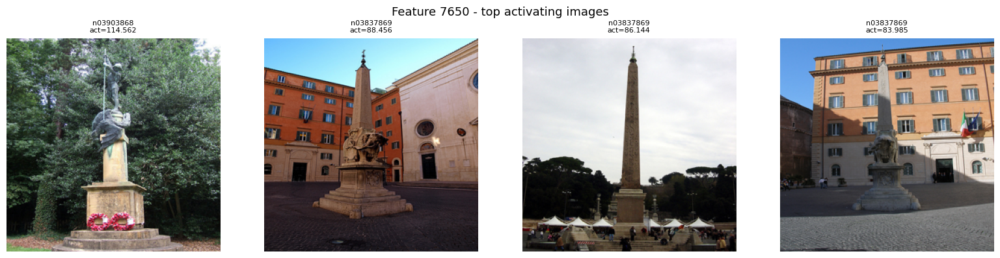

In [7]:
dataset_plain = ImageFolder(IMAGENET_VAL) 
transform     = make_transform()

img_patches = {}
for val, img_idx, patch_idx in entries:
    if img_idx not in img_patches:
        img_patches[img_idx] = {"max_val": val, "patches": []}
    img_patches[img_idx]["max_val"] = max(img_patches[img_idx]["max_val"], val)
    img_patches[img_idx]["patches"].append(patch_idx)

top_imgs = sorted(img_patches.items(), key=lambda x: -x[1]["max_val"])[:N_IMAGES]

print(f"Top {len(top_imgs)} images for feature {FEATURE_ID}:")
for img_idx, info in top_imgs:
    path, label = dataset_plain.samples[img_idx]
    cls = dataset_plain.classes[label]
    print(f"  img {img_idx:6d}  {cls:35s}  max_act={info['max_val']:.4f}  patches={info['patches']}")

ncols = 4
nrows = (len(top_imgs) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.array(axes).reshape(nrows, ncols)
fig.suptitle(f"Feature {FEATURE_ID} - top activating images", fontsize=13)
for i, (img_idx, info) in enumerate(top_imgs):
    path, label_idx = dataset_plain.samples[img_idx]
    cls = dataset_plain.classes[label_idx]
    pil = Image.open(path).convert("RGB").resize((256, 256))
    ax = axes[i // ncols, i % ncols]
    ax.imshow(pil)
    ax.set_title(f"{cls}\nact={info['max_val']:.3f}", fontsize=8)
    ax.axis("off")
for i in range(len(top_imgs), nrows * ncols):
    axes[i // ncols, i % ncols].axis("off")
plt.tight_layout()
plt.show()

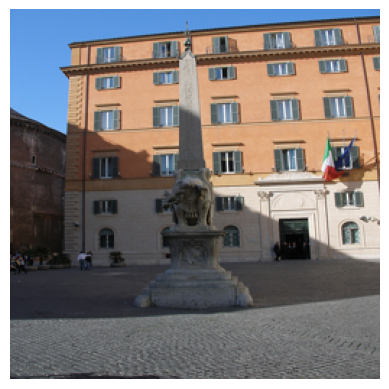

In [8]:
img_idx_2, info_2 = top_imgs[3]
path, label_idx_2 = dataset_plain.samples[img_idx_2]
pil_2 = Image.open(path).convert("RGB").resize((256, 256))
plt.imshow(pil_2)
plt.axis("off")
plt.show()

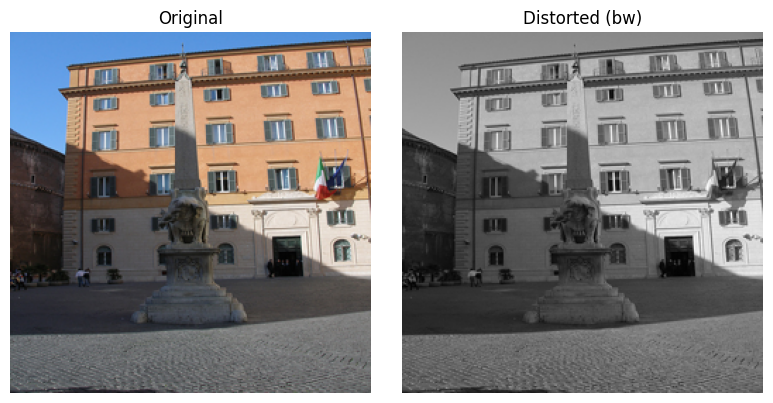

In [9]:
DISTORTION = "bw"

if DISTORTION == "blur":
    from PIL import ImageFilter
    pil_dist = pil_2.filter(ImageFilter.GaussianBlur(radius=5))

elif DISTORTION == "noise":
    import numpy as np
    arr  = np.array(pil_2).astype(np.float32)
    arr += np.random.normal(0, 30, arr.shape)
    pil_dist = Image.fromarray(arr.clip(0, 255).astype(np.uint8))

elif DISTORTION == "bw":
    pil_dist = pil_2.convert("L").convert("RGB")

elif DISTORTION == "jpeg":
    import io
    buf = io.BytesIO()
    pil_2.save(buf, format="JPEG", quality=5)
    pil_dist = Image.open(buf).convert("RGB")

transform    = make_transform()
tensor_orig  = transform(pil_2).unsqueeze(0).to(device)
tensor_dist  = transform(pil_dist).unsqueeze(0).to(device)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(pil_2); axes[0].set_title("Original");              axes[0].axis("off")
axes[1].imshow(pil_dist); axes[1].set_title(f"Distorted ({DISTORTION})"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## Experiment 2: (inspired by Daujotas 2024) 

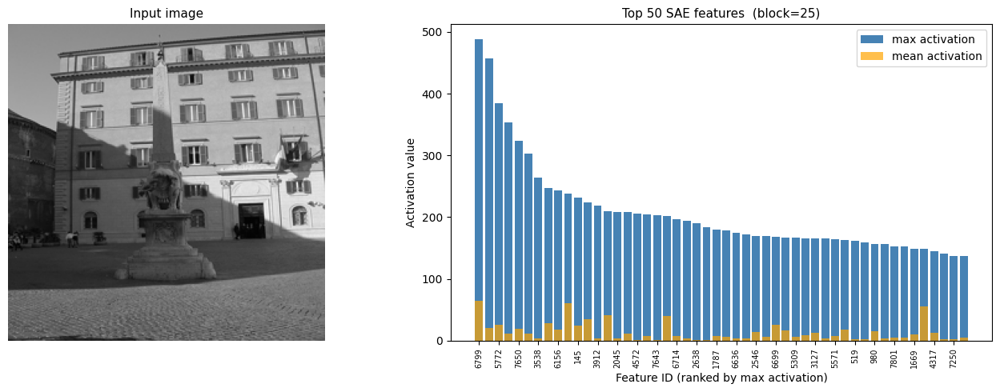

  # 1  feature  6799  max=487.991  mean=64.861
  # 2  feature  7196  max=457.533  mean=20.289
  # 3  feature  5772  max=384.371  mean=25.351
  # 4  feature   485  max=353.643  mean=10.810
  # 5  feature  7650  max=323.061  mean=19.482
  # 6  feature   114  max=302.469  mean=11.307
  # 7  feature  3538  max=263.801  mean=4.051
  # 8  feature  2541  max=246.547  mean=27.990
  # 9  feature  6156  max=243.773  mean=18.135
  #10  feature  6888  max=238.171  mean=60.799
  #11  feature   145  max=231.211  mean=23.940
  #12  feature  1057  max=223.647  mean=34.730
  #13  feature  3912  max=218.823  mean=3.248
  #14  feature  4162  max=209.103  mean=41.169
  #15  feature  2045  max=208.645  mean=3.350
  #16  feature   647  max=208.620  mean=11.495
  #17  feature  4572  max=205.076  mean=1.418
  #18  feature  6491  max=204.126  mean=7.855
  #19  feature  7643  max=202.567  mean=0.791
  #20  feature   843  max=201.889  mean=39.274
  #21  feature  6714  max=196.764  mean=7.191
  #22  feature  3195

In [10]:
IMAGE_PATH = "/scratch/work/vuh12/UniTok/sae/castlewithsun.jpg"   # ← change this

pil        = Image.open(IMAGE_PATH).convert("RGB")
img_tensor = make_transform()(pil_2).unsqueeze(0).to(device)

# fids, max_acts, mean_acts = get_top_features(img_tensor, k=50)
fids, max_acts, mean_acts = get_top_features(tensor_dist, k=50)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(pil_dist.resize((256, 256)))
# axes[0].imshow(pil_2.resize((256, 256)))
axes[0].set_title("Input image", fontsize=11)
axes[0].axis("off")

ranks = list(range(50))
axes[1].bar(ranks, max_acts, color="steelblue", label="max activation")
axes[1].bar(ranks, mean_acts, color="orange", alpha=0.7, label="mean activation")
axes[1].set_xticks(ranks[::2])
axes[1].set_xticklabels([str(fids[i]) for i in range(0, 50, 2)], rotation=90, fontsize=7)
axes[1].set_xlabel("Feature ID (ranked by max activation)")
axes[1].set_ylabel("Activation value")
axes[1].set_title(f"Top 50 SAE features  (block={BLOCK})", fontsize=11)
axes[1].legend()
plt.tight_layout()
# plt.savefig(os.path.join(OUTPUT_DIR, "top50_features.png"), dpi=150, bbox_inches="tight")
plt.show()

for rank, (fid, mv, av) in enumerate(zip(fids, max_acts, mean_acts), 1):
    print(f"  #{rank:2d}  feature {fid:5d}  max={mv:.3f}  mean={av:.3f}")

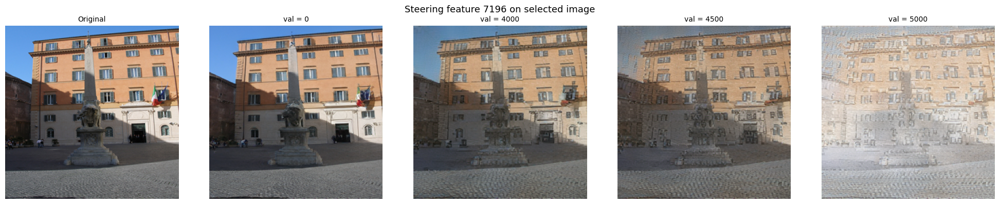

In [11]:
STEER_FEATURE_ID = fids[1]
# STEER_VALUES_HERE = [0.0, 10.0, 20.0, 40.0]
STEER_VALUES = [0.0, 4000.0, 4500.0, 5000.0]

fig, axes = plt.subplots(1, 1 + len(STEER_VALUES), figsize=(4 * (1 + len(STEER_VALUES)), 4))
fig.suptitle(f"Steering feature {STEER_FEATURE_ID} on selected image", fontsize=13)

axes[0].imshow(pil_2.resize((256, 256)))
axes[0].set_title("Original", fontsize=10)
axes[0].axis("off")

for ax, val in zip(axes[1:], STEER_VALUES):
    result = steer_forward(img_tensor, {STEER_FEATURE_ID: val})[0]
    # result = steer_forward(tensor_dist, {STEER_FEATURE_ID: val})[0]
    ax.imshow(to_np(result))
    ax.set_title(f"val = {val:.0f}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"steer_f{STEER_FEATURE_ID:05d}_from_top50.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
sys.path.insert(0, str(_root))
from sae.image_umap import extract_image_features, build_image_umap_html

feature_acts = extract_image_features(sae, unitok, img_tensor, block=BLOCK)
print(f"Active features: {len(feature_acts)}   max act: {max(feature_acts.values()):.2f}")

html = build_image_umap_html(
    feature_acts,
    umap_coords_path  = UMAP_COORDS_PATH,
    heap_results_path = HEAP_RESULTS_PATH,
    imagenet_val_path = IMAGENET_VAL,
    query_img_tensor  = img_tensor,
    thumb_px          = UMAP_THUMB_PX,
    n_show            = UMAP_N_SHOW,
    height            = "680px",
)
with open(UMAP_OUTPUT_PATH, "w", encoding="utf-8") as f:
    f.write(html)
print(f"Saved → {UMAP_OUTPUT_PATH}  ({len(html) // 1024} KB)")

## Inject feature(s) on random images that may not have that feature

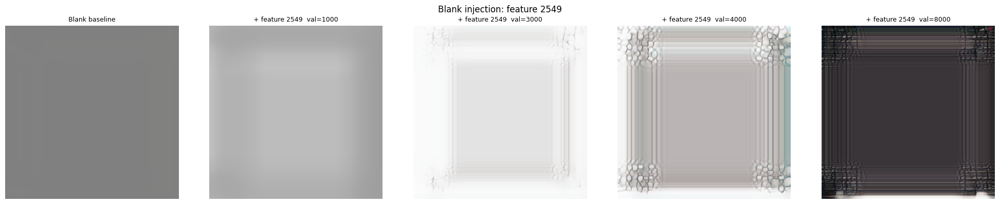

In [31]:
# INJECT_FEATURE_ID  = FEATURE_ID      # or specify a different feature
# INJECT_VALUES      = [0.0, 100.0, 500.0, 2000.0]
FEATURE_ID = 2549
INJECT_FEATURES    = {FEATURE_ID: 200.0}  # ← {feature_id: value, ...} - study features
INJECT_VALS_SWEEP  = [1000.0, 3000.0, 4000.0, 8000.0]  # sweep (used when len==1)
INJECT_ALL_PATCHES = True

DENSE_FEATURES_PATH = str(_root / "sae/dense_features.pt")
USE_DENSE_FEATURES  = False    # ← set False to inject study features only
DENSE_FEATURE_VAL   = 500.0   # activation value to inject each dense feature at

# Load dense features
dense_interventions = {}
if USE_DENSE_FEATURES:
    if os.path.exists(DENSE_FEATURES_PATH):
        _df = torch.load(DENSE_FEATURES_PATH, map_location="cpu")
        dense_interventions = {int(fid): DENSE_FEATURE_VAL for fid in _df["dense_features"].tolist()}
        print(f"Loaded {len(dense_interventions)} dense features  (threshold={_df['threshold']})")
    else:
        print(f"Dense features file not found: {DENSE_FEATURES_PATH}")
        print("Run: python sae/find_dense_features.py --checkpoint ... --unitok_ckpt ... --imagenet_val ...")
        
blank = torch.zeros(1, 3, 256, 256).to(device)   # gray (0 in [-1,1])
# Alternatives:
# blank = torch.full((1, 3, 256, 256), -1.0).to(device)  # black
# blank = torch.full((1, 3, 256, 256),  1.0).to(device)  # white

# fig, axes = plt.subplots(1, len(INJECT_VALUES), figsize=(4 * len(INJECT_VALUES), 4))
# fig.suptitle(
#     f"Feature {INJECT_FEATURE_ID} injected into blank image  "
#     f"({'all patches' if INJECT_ALL_PATCHES else 'center patch only'})",
#     fontsize=12,
# )
# for ax, val in zip(axes, INJECT_VALUES):
#     result = steer_forward(blank, {INJECT_FEATURE_ID: val}, all_patches=INJECT_ALL_PATCHES)[0]
#     ax.imshow(to_np(result))
#     ax.set_title(f"val = {val:.0f}", fontsize=9)
#     ax.axis("off")

# plt.tight_layout()
if len(INJECT_FEATURES) == 1:
    # Single study feature: sweep across INJECT_VALS_SWEEP
    fid_single = list(INJECT_FEATURES.keys())[0]
    extra_cols  = 1 if USE_DENSE_FEATURES else 0   # "dense only" column
    ncols = 1 + extra_cols + len(INJECT_VALS_SWEEP)

    fig, axes = plt.subplots(1, ncols, figsize=(4 * ncols, 4))
    fig.suptitle(
        f"Blank injection: feature {fid_single}"
        + (f"  +  {len(dense_interventions)} dense features" if USE_DENSE_FEATURES else ""),
        fontsize=12,
    )
    col = 0
    axes[col].imshow(to_np(baseline_forward(blank)[0]))
    axes[col].set_title("Blank baseline", fontsize=9)
    axes[col].axis("off")
    col += 1

    if USE_DENSE_FEATURES:
        axes[col].imshow(to_np(steer_forward(blank, dense_interventions, INJECT_ALL_PATCHES)[0]))
        axes[col].set_title("Dense only", fontsize=9)
        axes[col].axis("off")
        col += 1

    for val in INJECT_VALS_SWEEP:
        combined = {**dense_interventions, fid_single: val}
        axes[col].imshow(to_np(steer_forward(blank, combined, INJECT_ALL_PATCHES)[0]))
        axes[col].set_title(f"+ feature {fid_single}  val={val:.0f}", fontsize=9)
        axes[col].axis("off")
        col += 1

else:
    # Multiple study features: blank | dense only | dense + all study features
    extra_cols = 1 if USE_DENSE_FEATURES else 0
    ncols = 1 + extra_cols + 1
    fig, axes = plt.subplots(1, ncols, figsize=(4 * ncols, 4))
    fig.suptitle("Blank injection: multiple features", fontsize=12)
    col = 0
    axes[col].imshow(to_np(baseline_forward(blank)[0]))
    axes[col].set_title("Blank baseline", fontsize=9)
    axes[col].axis("off")
    col += 1

    if USE_DENSE_FEATURES:
        axes[col].imshow(to_np(steer_forward(blank, dense_interventions, INJECT_ALL_PATCHES)[0]))
        axes[col].set_title("Dense only", fontsize=9)
        axes[col].axis("off")
        col += 1

    combined = {**dense_interventions, **INJECT_FEATURES}
    axes[col].imshow(to_np(steer_forward(blank, combined, INJECT_ALL_PATCHES)[0]))
    axes[col].set_title(f"Dense + {list(INJECT_FEATURES.keys())}", fontsize=8)
    axes[col].axis("off")

plt.tight_layout()
fids_str = "_".join(str(f) for f in INJECT_FEATURES)
# out = os.path.join(OUTPUT_DIR, f"blank_inject_f{fids_str}.png")
# plt.savefig(out, dpi=150, bbox_inches="tight")
# print(f"Saved → {out}")
plt.show()

Image #37447  class=n04026417
  feature 7196: not active in this image (max=0)
Saved → /scratch/work/vuh12/UniTok/sae/analysis/ablation/inject_real_img37447.png


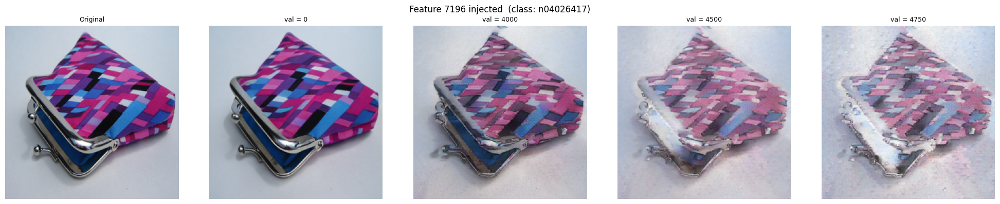

In [29]:
import random
INJECT_FEATURES    = {7196: 200.0}             # {feature_id: value, ...}
INJECT_VALS_SWEEP  = [0.0, 4000.0, 4500.0, 4750.0]  # sweep values (used when only 1 feature)

dataset_inj = ImageFolder(IMAGENET_VAL)
random.seed(10)   # change seed for a different random image
rand_idx = random.randint(0, len(dataset_inj) - 1)
path_inj, label_inj = dataset_inj.samples[rand_idx]
cls_inj  = dataset_inj.classes[label_inj]
pil_inj  = Image.open(path_inj).convert("RGB")
img_inj  = make_transform()(pil_inj).unsqueeze(0).to(device)
print(f"Image #{rand_idx}  class={cls_inj}")

_cap = {}
def _probe_hook(module, inp, out):
    B, L, D = out.shape
    acts_flat = out.float().reshape(B * L, D)
    latent, *_ = sae.encode(acts_flat)
    _cap["latent"] = latent.cpu()
_h = unitok.encoder.blocks[BLOCK].register_forward_hook(_probe_hook)
with torch.no_grad():
    unitok.encoder(img_inj)
_h.remove()
_lat = _cap["latent"]   # (L, hidden_dim)
for fid in INJECT_FEATURES:
    vals = _lat[:, fid]   # (L,) — one value per patch
    mx, mn = vals.max().item(), vals.mean().item()
    if mx > 0:
        print(f"  feature {fid}: already active  max={mx:.3f}  mean={mn:.3f}")
    else:
        print(f"  feature {fid}: not active in this image (max=0)")
        
if len(INJECT_FEATURES) == 1:
    # Single-feature sweep across INJECT_VALS_SWEEP
    fid_single = list(INJECT_FEATURES.keys())[0]
    ncols = 1 + len(INJECT_VALS_SWEEP)
    fig, axes = plt.subplots(1, ncols, figsize=(4 * ncols, 4))
    fig.suptitle(f"Feature {fid_single} injected  (class: {cls_inj})", fontsize=12)
    axes[0].imshow(pil_inj.resize((256, 256)))
    axes[0].set_title("Original", fontsize=9)
    axes[0].axis("off")
    for ax, val in zip(axes[1:], INJECT_VALS_SWEEP):
        result = steer_forward(img_inj, {fid_single: val}, all_patches=True)[0]
        ax.imshow(to_np(result))
        ax.set_title(f"val = {val:.0f}", fontsize=9)
        ax.axis("off")
else:
    # Multi-feature: original vs steered side by side
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    fig.suptitle(f"Multi-feature injection  (class: {cls_inj})", fontsize=12)
    result = steer_forward(img_inj, INJECT_FEATURES)[0]
    axes[0].imshow(pil_inj.resize((256, 256)))
    axes[0].set_title("Original", fontsize=9)
    axes[0].axis("off")
    axes[1].imshow(to_np(result))
    axes[1].set_title(str(INJECT_FEATURES), fontsize=8)
    axes[1].axis("off")

plt.tight_layout()
out = os.path.join(OUTPUT_DIR, f"inject_real_img{rand_idx}.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")
plt.show()

## Others

indices shape: torch.Size([1, 8, 256])
indices: tensor([[[1834, 2201, 2019,  ..., 2198,  633, 3219],
         [3440, 1285, 2950,  ..., 2423,  115, 4090],
         [3350, 3665,  620,  ..., 1801,  620, 1181],
         ...,
         [1053, 3884,  897,  ...,  458,  432, 1582],
         [1473, 3064, 2201,  ..., 2799, 2201, 1454],
         [1632, 2926, 2195,  ..., 1632, 2118, 2006]]], device='cuda:0')
indices shape: torch.Size([1, 8, 256])
indices: tensor([[[1514, 1462, 2019,  ..., 3003, 2706, 1147],
         [ 462, 1546, 3943,  ..., 1497, 3440,   94],
         [2701, 2715,  746,  ..., 2132, 3350,  768],
         ...,
         [3560, 3560, 1584,  ..., 2491,  897, 2142],
         [1230, 2936, 2936,  ..., 3637, 2201, 1454],
         [1762, 2640, 2987,  ..., 3765, 3616, 2409]]], device='cuda:0')
indices shape: torch.Size([1, 8, 256])
indices: tensor([[[2316, 1462, 2019,  ..., 2843, 3345, 1462],
         [1448, 2484, 3943,  ..., 1497, 3119,   94],
         [2701, 2715, 3473,  ...,  778, 3853, 30

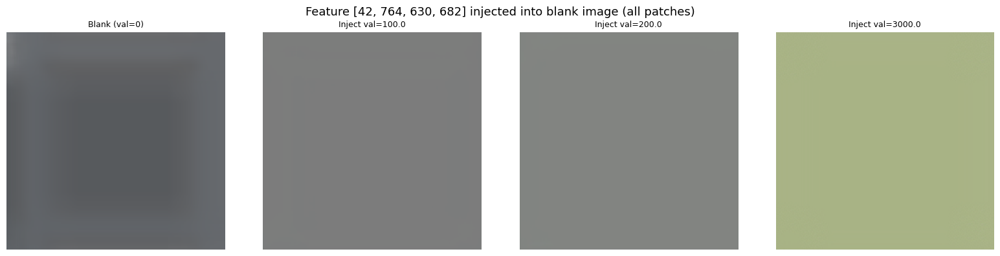

In [61]:
# inject a blank image
INJECT_FEATURE_ID = [42, 764, 630, 682]    # feature to inject
INJECT_VALUE      = 20.0   # activation value to set (try 5, 10, 20)
INJECT_ALL_PATCHES = False  # True = inject into every patch; False = center patch only

@torch.no_grad()
def inject_feature_forward(imgs, injections: dict, all_patches: bool = True):
    """
    injections: {feature_id: value} - directly sets feature values in the SAE latent.
    all_patches: if True, inject into all 64 patches; if False, only the center patch.

    Use this instead of multi_feature_forward when the base activation is 0.
    """
    def _hook(module, inp, out):
        B, L, D = out.shape
        acts_flat = out.float().reshape(B * L, D)
        latent, _, _, _ = sae.encode(acts_flat)  # (B*L, hidden_dim)
        for fid, val in injections.items():
            if all_patches:
                latent[:, fid] = val
            else:
                center = L // 2
                patch_indices = [b * L + center for b in range(B)]
                latent[patch_indices, fid] = val
        recon = sae.decode(latent).reshape(B, L, D)
        return recon.to(out.dtype)

    handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
    try:
        img_tokens = unitok.encoder(imgs).float()
        img_tokens = unitok.quant_proj(img_tokens)
        indices =unitok.quantizer.f_to_idx(img_tokens)
        img_tokens, _, _, _ = unitok.quantizer(img_tokens)
        print(f"indices shape: {indices.shape}")
        print(f"indices: {indices}")

        img_tokens = unitok.post_quant_proj(img_tokens)
        img_rec    = unitok.decoder(img_tokens).clamp(-1, 1)
    finally:
        handle.remove()
    return denorm(img_rec)


blank = torch.zeros(1, 3, 256, 256).to(device)  # 0 in [-1,1] = gray

# Also try: pure black = -1, pure white = 1
# blank = torch.full((1, 3, 256, 256), -1.0).to(device)
# blank = torch.full((1, 3, 256, 256),  1.0).to(device)

inject_values = [0.0, 100.0, 200.0, 3000.0]

fig, axes = plt.subplots(1, len(inject_values), figsize=(4 * len(inject_values), 4))
fig.suptitle(f"Feature {INJECT_FEATURE_ID} injected into blank image (all patches)", fontsize=13)

for ax, val in zip(axes, inject_values):
    if val == 0.0:
        # No injection, just run SAE recon on blank (should stay gray)
        result = inject_feature_forward(blank, {a: val for a in CLUSTER_TOP_FEATURES})
        ax.set_title(f"Blank (val=0)", fontsize=9)
    else:
        result = inject_feature_forward(blank, {a: val for a in CLUSTER_TOP_FEATURES})
                                
        ax.set_title(f"Inject val={val}", fontsize=9)
    ax.imshow(to_np(result[0]))
    ax.axis("off")

plt.tight_layout()
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")
plt.show()

In [62]:
# Config for swap experiment
BIRD_FEATURE   = 748   # feature 00748: birds
WATERMARK_FEATURE = 682   # feature 682: iStockphoto watermark
WATERMARK_SCALE   = 50.0   # move around
SWAP_N_IMAGES  = 4     
SWAP_SCAN_LIMIT = 5000 


@torch.no_grad()
def multi_feature_forward(imgs, feature_scales: dict):
    """
    Run UniTok with an SAE hook that applies different scales to multiple features.

    feature_scales: {feature_id: scale}
        e.g. {748: 0.0, 730: 5.0}  -> ablate 748, amplify 730

    Returns reconstructed images in [0,1], shape (B,3,H,W).
    """
    def _hook(module, inp, out):
        B, L, D = out.shape
        acts_flat = out.float().reshape(B * L, D)
        latent, _, _, _ = sae.encode(acts_flat)
        for fid, scale in feature_scales.items():
            latent[:, fid] = latent[:, fid] * scale
        recon = sae.decode(latent).reshape(B, L, D)
        return recon.to(out.dtype)

    handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
    try:
        img_tokens = unitok.encoder(imgs).float()
        img_tokens = unitok.quant_proj(img_tokens)
        img_tokens, _, _, _ = unitok.quantizer(img_tokens)
        img_tokens = unitok.post_quant_proj(img_tokens)
        img_rec    = unitok.decoder(img_tokens).clamp(-1, 1)
    finally:
        handle.remove()
    return denorm(img_rec)

In [63]:
# Find top bird images (feature 748) and top iStockPhotos images (feature 682)
from sae.feature_analysis import find_max_activating_examples

print(f"Scanning {SWAP_SCAN_LIMIT} val images for features {BIRD_FEATURE} and {WATERMARK_FEATURE}")

swap_results = find_max_activating_examples(
    sae              = sae,
    unitok           = unitok,
    imagenet_val_dir = IMAGENET_VAL,
    feature_indices  = [BIRD_FEATURE, WATERMARK_FEATURE],
    k_top            = 32,
    img_batch        = 32,
    device           = device,
)

def top_images_for_feature(results, fid, n):
    img_patches = {}
    for val, img_idx, patch_idx in results[fid]:
        if img_idx not in img_patches:
            img_patches[img_idx] = {"max_val": val, "patches": []}
        img_patches[img_idx]["max_val"] = max(img_patches[img_idx]["max_val"], val)
        img_patches[img_idx]["patches"].append(patch_idx)
    return sorted(img_patches.items(), key=lambda x: -x[1]["max_val"])[:n]

bird_top   = top_images_for_feature(swap_results, BIRD_FEATURE,   SWAP_N_IMAGES)
watermark_top = top_images_for_feature(swap_results, WATERMARK_FEATURE, SWAP_N_IMAGES)

dataset_plain = ImageFolder(IMAGENET_VAL)

print(f"\nTop {len(bird_top)} bird images (feature {BIRD_FEATURE}):")
for img_idx, info in bird_top:
    path, label = dataset_plain.samples[img_idx]
    print(f"  img {img_idx:6d}  {dataset_plain.classes[label]:35s}  max_act={info['max_val']:.4f}")

print(f"\nTop {len(watermark_top)} watermark images (feature {WATERMARK_FEATURE}):")
for img_idx, info in watermark_top:
    path, label = dataset_plain.samples[img_idx]
    print(f"  img {img_idx:6d}  {dataset_plain.classes[label]:35s}  max_act={info['max_val']:.4f}")

Scanning 5000 val images for features 748 and 682


feature analysis: 100%|██████████| 1563/1563 [09:50<00:00,  2.65it/s]



Top 4 bird images (feature 748):
  img    654  n01534433                            max_act=192.1431
  img    650  n01534433                            max_act=188.5128
  img    697  n01534433                            max_act=184.6436
  img    665  n01534433                            max_act=184.1424

Top 4 watermark images (feature 682):
  img  40503  n04264628                            max_act=41.5812
  img  39155  n04153751                            max_act=38.8977
  img  21886  n02814860                            max_act=37.1926
  img  39277  n04162706                            max_act=36.8181


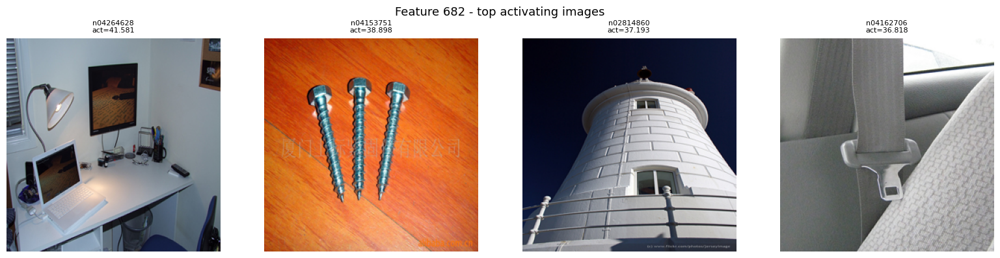

In [64]:
ncols = 4
nrows = (len(watermark_top) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.array(axes).reshape(nrows, ncols)
fig.suptitle(f"Feature {WATERMARK_FEATURE} - top activating images", fontsize=13)
for i, (img_idx, info) in enumerate(watermark_top):
    path, label_idx = dataset_plain.samples[img_idx]
    cls = dataset_plain.classes[label_idx]
    pil = Image.open(path).convert("RGB").resize((256, 256))
    ax = axes[i // ncols, i % ncols]
    ax.imshow(pil)
    ax.set_title(f"{cls}\nact={info['max_val']:.3f}", fontsize=8)
    ax.axis("off")
for i in range(len(watermark_top), nrows * ncols):
    axes[i // ncols, i % ncols].axis("off")
plt.tight_layout()
plt.show()

Saved to /scratch/work/vuh12/UniTok/sae/analysis/ablation/swap_bird748_watermark682_x50.0.png


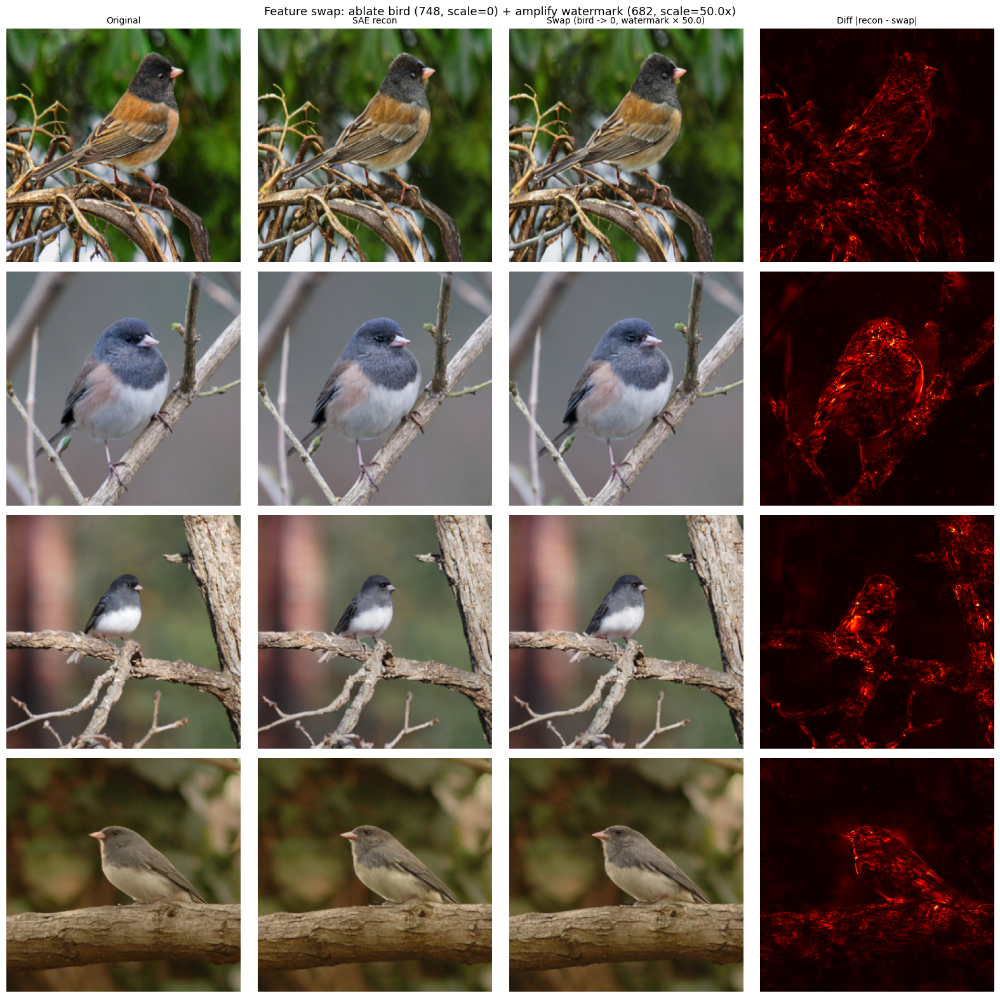

In [65]:
# Bird to watermark swap  
transform = make_transform()
n = len(bird_top)

fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
if n == 1:
    axes = axes[np.newaxis, :]

fig.suptitle(
    f"Feature swap: ablate bird ({BIRD_FEATURE}, scale=0) + amplify watermark ({WATERMARK_FEATURE}, scale={WATERMARK_SCALE}x)",
    fontsize=13,
)
for col, title in enumerate(["Original", "SAE recon", f"Swap (bird -> 0, watermark × {WATERMARK_SCALE})", "Diff |recon - swap|"]):
    axes[0, col].set_title(title, fontsize=10)

for row, (img_idx, info) in enumerate(bird_top):
    path, label_idx = dataset_plain.samples[img_idx]
    cls = dataset_plain.classes[label_idx]

    pil        = Image.open(path).convert("RGB")
    img_tensor = transform(pil).unsqueeze(0).to(device)

    sae_recon = multi_feature_forward(img_tensor, {BIRD_FEATURE: 1.0, WATERMARK_FEATURE: 1.0})
    swapped   = multi_feature_forward(img_tensor, {BIRD_FEATURE: 0.0, WATERMARK_FEATURE: WATERMARK_SCALE})

    diff = (sae_recon - swapped).abs().mean(dim=1, keepdim=True)
    diff_norm = (diff / diff.max().clamp_min(1e-8))[0, 0].cpu().numpy()

    axes[row, 0].imshow(to_np(denorm(img_tensor)[0]))
    axes[row, 1].imshow(to_np(sae_recon[0]))
    axes[row, 2].imshow(to_np(swapped[0]))
    axes[row, 3].imshow(diff_norm, cmap="hot", vmin=0, vmax=1)
    axes[row, 0].set_ylabel(f"img {img_idx}\n{cls}\nbird_act={info['max_val']:.3f}", fontsize=8)
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
out = os.path.join(OUTPUT_DIR, f"swap_bird{BIRD_FEATURE}_watermark{WATERMARK_FEATURE}_x{WATERMARK_SCALE}.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved to {out}")
plt.show()

In [66]:
# distort images and see what changes
import torchvision.transforms.functional as TF
from PIL import ImageDraw, ImageFont

# Helper: extract SAE latent for an image (no recon)
@torch.no_grad()
def get_sae_latent(img_tensor):
    """
    Returns SAE latent averaged over all 64 patches: shape (hidden_dim,)
    img_tensor: (1, 3, 256, 256) in [-1, 1]
    """
    act_buffer = []
    def _hook(module, inp, out):
        act_buffer.append(out.detach())
    handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
    with torch.no_grad():
        _ = unitok.encoder(img_tensor)
    handle.remove()
    acts = act_buffer[0].float()          # (1, 64, 1024)
    B, L, D = acts.shape
    latent, _, _, _ = sae.encode(acts.reshape(B * L, D))  # (64, 8192)
    latent = latent.reshape(B, L, -1)[0]              # (64, 8192)
    return latent.max(0).values, latent.mean(0)       # both (8192,)


# Helper functions for distortions 
def to_pil(tensor):
    """(1,3,H,W) in [-1,1] → PIL image"""
    return TF.to_pil_image(denorm(tensor[0]).cpu())

def distort_bw(pil):
    return pil.convert("L").convert("RGB")

def distort_noise(pil, std=0.15):
    t = TF.to_tensor(pil)
    t = (t + torch.randn_like(t) * std).clamp(0, 1)
    return TF.to_pil_image(t)

def distort_blur(pil, radius=5):
    from PIL import ImageFilter
    return pil.filter(ImageFilter.GaussianBlur(radius=radius))

def distort_text(pil, text="HELLO"):
    pil = pil.copy()
    draw = ImageDraw.Draw(pil)
    draw.text((10, 10), text, fill=(255, 255, 255))
    return pil

def distort_flip(pil):
    return TF.hflip(pil)

def distort_jpeg(pil, quality=5):
    import io
    buf = io.BytesIO()
    pil.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB")

DISTORTIONS = {
    "grayscale":  distort_bw,
    "noise":      distort_noise,
    "blur":       distort_blur,
    "text":       distort_text,
    "h-flip":     distort_flip,
    "jpeg q=5":   distort_jpeg,
}

print(f"Distortions defined: {list(DISTORTIONS.keys())}")

Distortions defined: ['grayscale', 'noise', 'blur', 'text', 'h-flip', 'jpeg q=5']


Saved → /scratch/work/vuh12/UniTok/sae/analysis/ablation/distortion_delta_img654.png


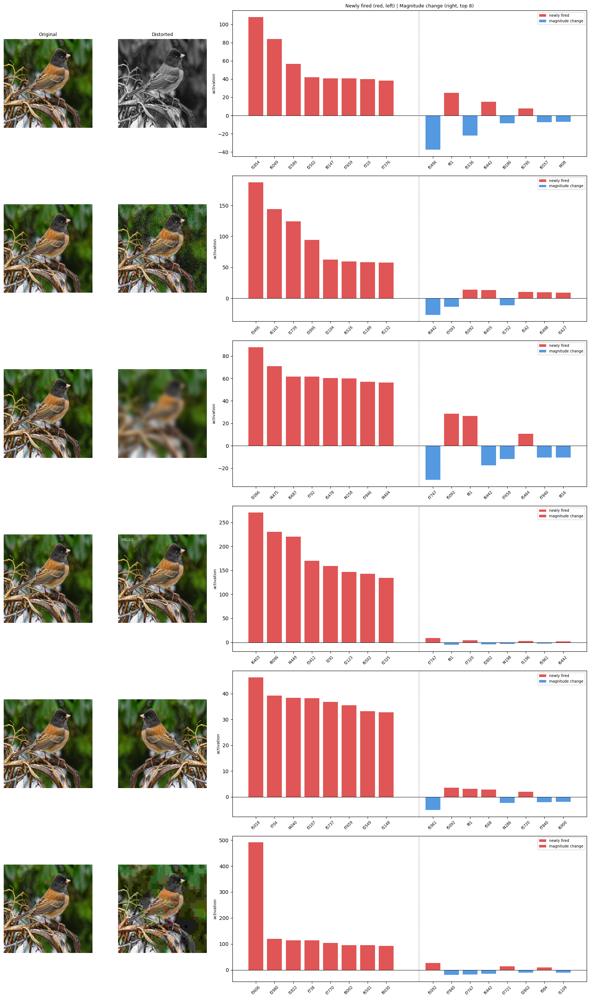

In [67]:
# Config
DISTORT_IMG_IDX = bird_top[0][0]  
TOP_K_FEATURES  = 8               

transform = make_transform()
path, label_idx = dataset_plain.samples[DISTORT_IMG_IDX]
src_pil = Image.open(path).convert("RGB").resize((256, 256))
src_tensor = transform(src_pil).unsqueeze(0).to(device)
max_orig, mean_orig = get_sae_latent(src_tensor)
fired_orig = (max_orig > 0).cpu()  

n_dist = len(DISTORTIONS)
fig, axes = plt.subplots(n_dist, 3, figsize=(16, 4.5 * n_dist),
                         gridspec_kw={"width_ratios": [1, 1, 4]})

for row, (name, fn) in enumerate(DISTORTIONS.items()):
    mod_pil    = fn(src_pil)
    mod_tensor = transform(mod_pil).unsqueeze(0).to(device)
    max_mod, mean_mod = get_sae_latent(mod_tensor)
    fired_mod = (max_mod > 0).cpu()

    new_mask  = (~fired_orig) & fired_mod          # (8192,) bool
    new_ids   = new_mask.nonzero(as_tuple=True)[0]
    new_vals  = max_mod.cpu()[new_ids]
    top_new   = new_vals.topk(min(TOP_K_FEATURES, len(new_vals)))
    new_feat_ids  = new_ids[top_new.indices].numpy()
    new_feat_vals = top_new.values.numpy()

    both_mask = fired_orig & fired_mod
    delta     = (mean_mod - mean_orig).cpu()
    delta_both = delta.clone()
    delta_both[~both_mask] = 0
    top_changed = delta_both.abs().topk(TOP_K_FEATURES)
    chg_feat_ids  = top_changed.indices.numpy()
    chg_feat_vals = delta_both[top_changed.indices].numpy()

    # Col 0: original
    axes[row, 0].imshow(src_pil)
    axes[row, 0].set_title("Original" if row == 0 else "", fontsize=9)
    axes[row, 0].set_ylabel(name, fontsize=11, fontweight="bold")
    axes[row, 0].axis("off")

    # Col 1: distorted + newly fired count
    axes[row, 1].imshow(mod_pil)
    axes[row, 1].set_title("Distorted" if row == 0 else "", fontsize=9)
    axes[row, 1].set_xlabel(f"{new_mask.sum().item()} new features fired", fontsize=8, color="#cc4444")
    axes[row, 1].axis("off")

    # Col 2: two grouped bar charts side by side
    ax = axes[row, 2]
    x_new = np.arange(len(new_feat_ids))
    x_chg = np.arange(len(chg_feat_ids)) + len(new_feat_ids) + 1.5  # gap between groups

    ax.bar(x_new, new_feat_vals, color="#e05555", label="newly fired")
    ax.bar(x_chg, chg_feat_vals,
           color=["#e05555" if v > 0 else "#5599e0" for v in chg_feat_vals],
           label="magnitude change")

    ax.axhline(0, color="black", linewidth=0.7)
    ax.axvline(len(new_feat_ids) + 0.75, color="gray", linewidth=0.7, linestyle="--")

    all_ids   = np.concatenate([new_feat_ids,  chg_feat_ids])
    all_x     = np.concatenate([x_new, x_chg])
    ax.set_xticks(all_x)
    ax.set_xticklabels([f"f{i}" for i in all_ids], rotation=45, fontsize=7)
    ax.set_ylabel("activation", fontsize=8)
    if row == 0:
        ax.set_title(f"Newly fired (red, left) | Magnitude change (right, top {TOP_K_FEATURES})", fontsize=9)
    ax.legend(fontsize=7, loc="upper right")

plt.tight_layout()
out = os.path.join(OUTPUT_DIR, f"distortion_delta_img{DISTORT_IMG_IDX}.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")
plt.show()

In [68]:
path, _ = dataset_plain.samples[DISTORT_IMG_IDX]
src_pil    = Image.open(path).convert("RGB").resize((256, 256))
src_tensor = transform(src_pil).unsqueeze(0).to(device)
max_orig, _ = get_sae_latent(src_tensor)
fired_orig   = (max_orig > 0).cpu()

jpeg_pil    = distort_jpeg(src_pil, quality=5)
jpeg_tensor = transform(jpeg_pil).unsqueeze(0).to(device)
max_jpeg, _ = get_sae_latent(jpeg_tensor)
fired_jpeg   = (max_jpeg > 0).cpu()

new_mask  = (~fired_orig) & fired_jpeg
new_ids   = new_mask.nonzero(as_tuple=True)[0]
new_vals  = max_jpeg.cpu()[new_ids]
top       = new_vals.topk(min(5, len(new_vals)))

print("Top newly fired features after JPEG compression:")
for rank, (idx, val) in enumerate(zip(new_ids[top.indices].tolist(), top.values.tolist())):
    print(f"  rank {rank+1}  feature {idx:5d}  max_act = {val:.2f}")

JPEG_FEATURE = int(new_ids[top.indices[0]])   # highest activation = top JPEG feature
print(f"\nUsing JPEG feature: {JPEG_FEATURE}")

Top newly fired features after JPEG compression:
  rank 1  feature  3606  max_act = 490.94
  rank 2  feature  2980  max_act = 119.43
  rank 3  feature  1822  max_act = 113.97
  rank 4  feature   738  max_act = 113.57
  rank 5  feature  7770  max_act = 103.58

Using JPEG feature: 3606


indices shape: torch.Size([1, 8, 256])
indices: tensor([[[2765,  733, 3117,  ..., 1241, 3745, 1847],
         [ 151, 1370, 2871,  ...,  960, 3490, 1066],
         [3784, 2023, 3926,  ..., 3586,  166,  496],
         ...,
         [3954, 3861,  507,  ..., 1962, 3875, 2501],
         [1237, 3114,  161,  ..., 2904, 1078, 3439],
         [3697, 2222, 1528,  ..., 2299, 2403, 3569]]], device='cuda:0')
indices shape: torch.Size([1, 8, 256])
indices: tensor([[[1001, 1053, 2280,  ..., 3440, 1001,  986],
         [1561, 2739, 2930,  ..., 3110, 1325,  807],
         [2910, 2522, 3926,  ..., 2996, 2273,  496],
         ...,
         [2528, 2952,  507,  ..., 1880, 2042, 2454],
         [2212, 1852, 2576,  ..., 3585, 1078,  537],
         [ 938, 3565, 3468,  ...,  139, 1751, 3469]]], device='cuda:0')
indices shape: torch.Size([1, 8, 256])
indices: tensor([[[4043, 3447, 3003,  ..., 1525,  626, 3003],
         [2851,  554,  765,  ..., 2902, 3964,  807],
         [2116, 1500, 1194,  ..., 3233,  895,  6

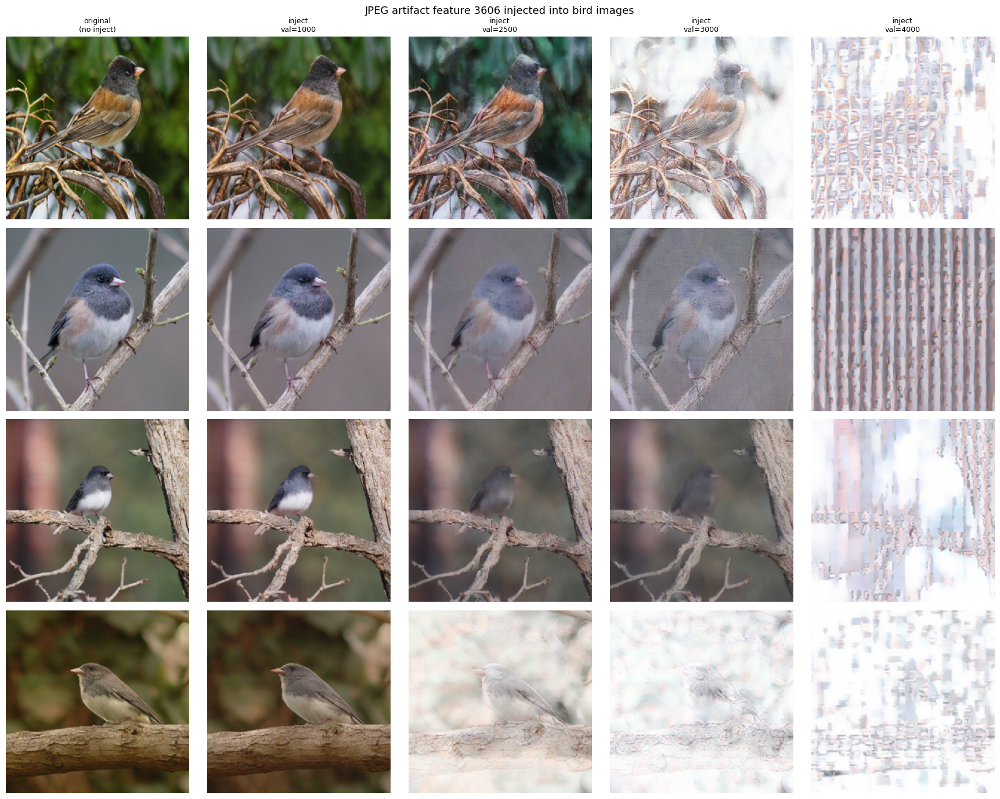

In [69]:
INJECT_STRENGTHS = [0.0, 1000.0, 2500.0, 3000.0, 4000.0]   
N_BIRD_IMAGES    = 4  

fig, axes = plt.subplots(N_BIRD_IMAGES, len(INJECT_STRENGTHS),
                         figsize=(3.5 * len(INJECT_STRENGTHS), 3.5 * N_BIRD_IMAGES))

for col, strength in enumerate(INJECT_STRENGTHS):
    axes[0, col].set_title(
        "original\n(no inject)" if strength == 0 else f"inject\nval={strength:.0f}",
        fontsize=9
    )

for row in range(N_BIRD_IMAGES):
    img_idx, info = bird_top[row]
    path, label_idx = dataset_plain.samples[img_idx]
    cls  = dataset_plain.classes[label_idx]
    pil  = Image.open(path).convert("RGB")
    tensor = transform(pil).unsqueeze(0).to(device)

    for col, strength in enumerate(INJECT_STRENGTHS):
        result = inject_feature_forward(tensor, {JPEG_FEATURE: strength},
                                        all_patches=True)
        axes[row, col].imshow(to_np(result[0]))
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(f"{cls}\nact={info['max_val']:.2f}", fontsize=8)

plt.suptitle(f"JPEG artifact feature {JPEG_FEATURE} injected into bird images", fontsize=13)
plt.tight_layout()
out = os.path.join(OUTPUT_DIR, f"jpeg_feature{JPEG_FEATURE}_steer.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")
plt.show()

indices shape: torch.Size([1, 8, 256])
indices: tensor([[[2765,  733, 3117,  ..., 1241, 3745, 1847],
         [ 151, 1370, 2871,  ...,  960, 3490, 1066],
         [3784, 2023, 3926,  ..., 3586,  166,  496],
         ...,
         [3954, 3861,  507,  ..., 1962, 3875, 2501],
         [1237, 3114,  161,  ..., 2904, 1078, 3439],
         [3697, 2222, 1528,  ..., 2299, 2403, 3569]]], device='cuda:0')
indices shape: torch.Size([1, 8, 256])
indices: tensor([[[2765,  733,  743,  ..., 1241, 3745, 1847],
         [ 151, 1370, 2871,  ...,  960, 3490, 1066],
         [3784, 2023, 3926,  ..., 1200,  166,  470],
         ...,
         [3954, 3861,  507,  ..., 1634, 3875, 3268],
         [1237, 3114,  161,  ..., 2904, 3362, 3439],
         [ 692, 1108, 1528,  ..., 2299, 2403, 3569]]], device='cuda:0')
indices shape: torch.Size([1, 8, 256])
indices: tensor([[[2765, 4078,   10,  ..., 1241, 3745, 1532],
         [ 151, 1370, 2871,  ...,  960, 3490, 1066],
         [1282, 2023, 3926,  ..., 1200,  166,  4

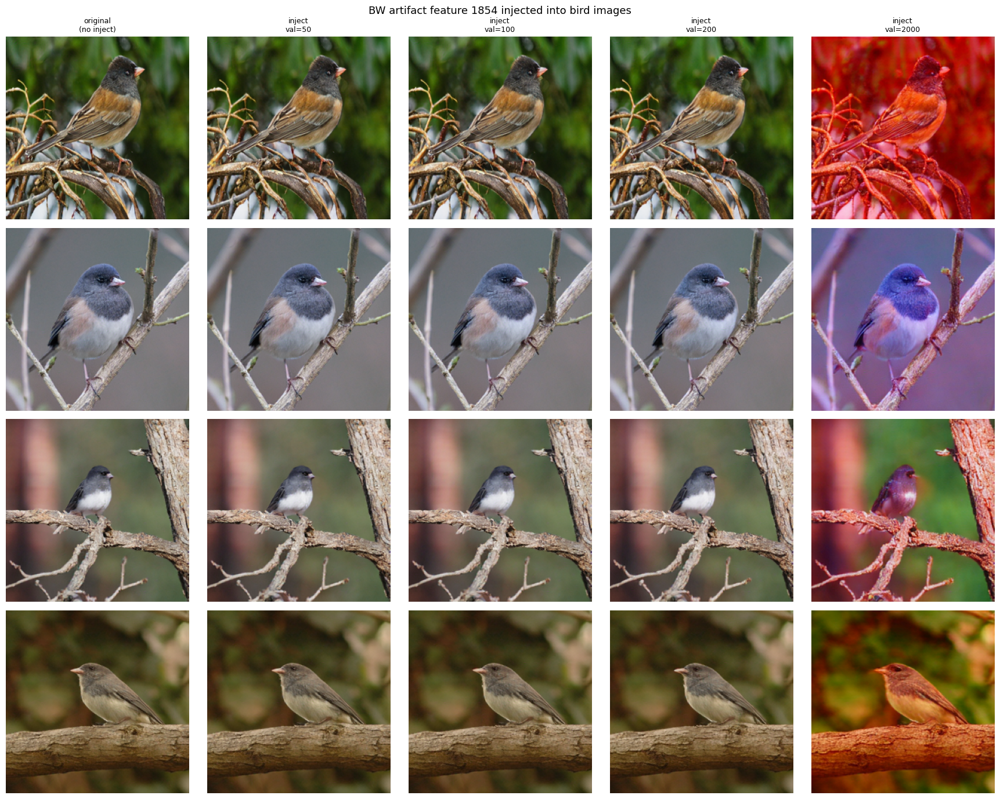

In [70]:
BW_FEATURE = 1854
INJECT_STRENGTHS = [0.0, 50.0, 100.0, 200.0, 2000.0]   
N_BIRD_IMAGES    = 4  

fig, axes = plt.subplots(N_BIRD_IMAGES, len(INJECT_STRENGTHS),
                         figsize=(3.5 * len(INJECT_STRENGTHS), 3.5 * N_BIRD_IMAGES))

for col, strength in enumerate(INJECT_STRENGTHS):
    axes[0, col].set_title(
        "original\n(no inject)" if strength == 0 else f"inject\nval={strength:.0f}",
        fontsize=9
    )

for row in range(N_BIRD_IMAGES):
    img_idx, info = bird_top[row]
    path, label_idx = dataset_plain.samples[img_idx]
    cls  = dataset_plain.classes[label_idx]
    pil  = Image.open(path).convert("RGB")
    tensor = transform(pil).unsqueeze(0).to(device)

    for col, strength in enumerate(INJECT_STRENGTHS):
        result = inject_feature_forward(tensor, {BW_FEATURE: strength},
                                        all_patches=True)
        axes[row, col].imshow(to_np(result[0]))
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(f"{cls}\nact={info['max_val']:.2f}", fontsize=8)

plt.suptitle(f"BW artifact feature {BW_FEATURE} injected into bird images", fontsize=13)
plt.tight_layout()
out = os.path.join(OUTPUT_DIR, f"bw_feature{JPEG_FEATURE}_steer.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")
plt.show()

indices shape: torch.Size([1, 8, 256])
indices: tensor([[[2765, 4078, 4046,  ..., 3133, 2317, 1625],
         [ 129, 1919,  843,  ..., 2325,  646, 2616],
         [1084, 2023, 3926,  ..., 1200,  166,  470],
         ...,
         [2966, 1927,  507,  ..., 1634,  503, 3565],
         [3891, 2062, 1724,  ...,  358, 2325, 1431],
         [3595, 2242, 3923,  ..., 1519, 1017, 1210]]], device='cuda:0')


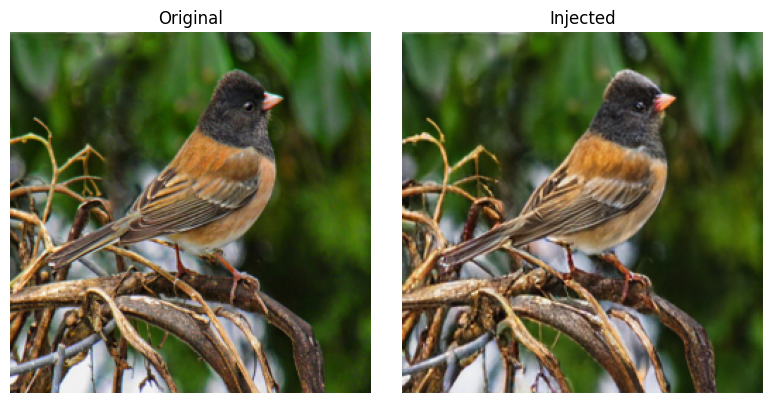

In [71]:
img_idx, info = bird_top[0]
path, _ = dataset_plain.samples[img_idx]
img_tensor = transform(Image.open(path).convert("RGB")).unsqueeze(0).to(device)

result = inject_feature_forward(
    img_tensor,
    injections={1854: 210.0, 6049: 160.0, 2589: 110.0, 2502: 80.0, 8147: 80.0, 7659: 80.0, 310: 80.0, 7376: 76.0},
    all_patches=True
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(to_np(denorm(img_tensor)[0])); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(to_np(result[0])); axes[1].set_title("Injected"); axes[1].axis("off")
plt.tight_layout()
plt.show()

In [72]:
print(dataset_plain.classes[:5])

['n01440764', 'n01443537', 'n01484850', 'n01491361', 'n01494475']


In [73]:
# Experiment: find a cluster of data that i know (ie: sun + senset + beach + sky), and i find the top-k activating features on that then try to ablate/steer them
# CLUSTER_KEYWORDS   = ["seashore", "sandbar", "lakeside", "promontory"]
CLUSTER_ID = {"n09428293", "n09421951", "n09332890", "n09399592"}
N_CLUSTER_IMAGES   = 100   
TOP_K_CLUSTER      = 10    
CLUSTER_SHOW_IMGS  = 4     

import random
random.seed(42)

matched_classes = {c for c in dataset_plain.classes if c in CLUSTER_ID}
print(f"Matched {len(matched_classes)} classes: {sorted(matched_classes)}")


cluster_indices = [
    idx for idx, (path, label) in enumerate(dataset_plain.samples)
    if dataset_plain.classes[label] in matched_classes
]
random.shuffle(cluster_indices)
cluster_indices = cluster_indices[:N_CLUSTER_IMAGES]
print(f"Using {len(cluster_indices)} images from cluster")

transform = make_transform()
feat_sum   = torch.zeros(sae.hidden_dim, device="cpu")  
feat_count = torch.zeros(sae.hidden_dim, device="cpu")  

for img_idx in tqdm(cluster_indices, desc="cluster scan"):
    path, _ = dataset_plain.samples[img_idx]
    pil = Image.open(path).convert("RGB")
    tensor = transform(pil).unsqueeze(0).to(device)
    max_lat, _ = get_sae_latent(tensor)
    max_lat = max_lat.cpu()
    feat_sum   += max_lat
    feat_count += (max_lat > 0).float()

feat_mean = feat_sum / len(cluster_indices)       
feat_freq = feat_count / len(cluster_indices)     

cluster_score = feat_mean * feat_freq
top_cluster   = cluster_score.topk(TOP_K_CLUSTER)

print(f"\nTop {TOP_K_CLUSTER} cluster features (score = mean_act × frequency):")
print(f"{'rank':>4}  {'feature':>7}  {'score':>8}  {'mean_act':>9}  {'freq':>6}")
for rank, (fid, score) in enumerate(zip(top_cluster.indices.tolist(), top_cluster.values.tolist())):
    print(f"{rank+1:>4}  {fid:>7}  {score:>8.3f}  {feat_mean[fid]:>9.3f}  {feat_freq[fid]:>6.2%}")

CLUSTER_TOP_FEATURES = top_cluster.indices.tolist()

Matched 4 classes: ['n09332890', 'n09399592', 'n09421951', 'n09428293']
Using 100 images from cluster


cluster scan:   0%|          | 0/100 [00:00<?, ?it/s]


Top 10 cluster features (score = mean_act × frequency):
rank  feature     score   mean_act    freq
   1     7747   654.234    654.234  100.00%
   2     6442   272.496    272.496  100.00%
   3       81   238.661    238.661  100.00%
   4     5092   176.057    176.057  100.00%
   5      116   136.328    136.328  100.00%
   6      542   131.139    141.009  93.00%
   7     5496   127.848    127.848  100.00%
   8     7840   118.933    118.933  100.00%
   9     7016   114.600    114.600  100.00%
  10     1117   109.552    111.788  98.00%


lakeside:   0%|          | 0/50 [00:00<?, ?it/s]

promontory:   0%|          | 0/50 [00:00<?, ?it/s]

sandbar:   0%|          | 0/50 [00:00<?, ?it/s]

seashore:   0%|          | 0/50 [00:00<?, ?it/s]

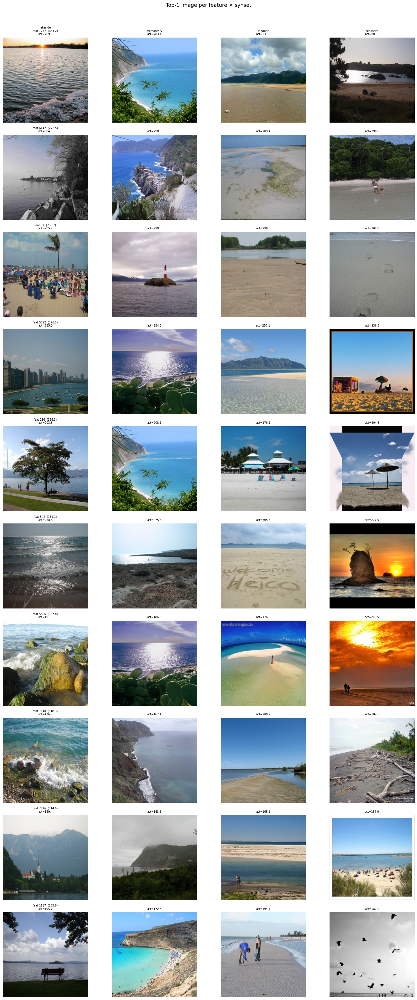

In [74]:
SYNSET_NAMES = {
    "n09332890": "lakeside",
    "n09399592": "promontory",
    "n09421951": "sandbar",
    "n09428293": "seashore",
}
synsets_ordered = sorted(matched_classes)

synset_indices = {syn: [] for syn in synsets_ordered}
for idx, (path, label) in enumerate(dataset_plain.samples):
    syn = dataset_plain.classes[label]
    if syn in synset_indices:
        synset_indices[syn].append(idx)

# best (activation, img_idx) per (feature, synset)
best = {fid: {syn: (0.0, None) for syn in synsets_ordered} for fid in CLUSTER_TOP_FEATURES}

for syn in synsets_ordered:
    for img_idx in tqdm(synset_indices[syn], desc=SYNSET_NAMES[syn]):
        path, _ = dataset_plain.samples[img_idx]
        tensor = transform(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
        max_lat, _ = get_sae_latent(tensor)
        max_lat = max_lat.cpu()
        for fid in CLUSTER_TOP_FEATURES:
            val = max_lat[fid].item()
            if val > best[fid][syn][0]:
                best[fid][syn] = (val, img_idx)

fig, axes = plt.subplots(len(CLUSTER_TOP_FEATURES), len(synsets_ordered),
                         figsize=(4 * len(synsets_ordered), 3.5 * len(CLUSTER_TOP_FEATURES)))

for row, fid in enumerate(CLUSTER_TOP_FEATURES):
    for col, syn in enumerate(synsets_ordered):
        ax = axes[row, col]
        val, img_idx = best[fid][syn]

        if img_idx is not None and val > 0:
            path, _ = dataset_plain.samples[img_idx]
            ax.imshow(Image.open(path).convert("RGB").resize((224, 224)))
        else:
            ax.imshow(np.zeros((224, 224, 3), dtype=np.uint8))

        title = []
        if row == 0:               title.append(SYNSET_NAMES[syn])
        if col == 0:               title.append(f"feat {fid}  ({cluster_score[fid]:.1f})")
        title.append(f"act={val:.1f}" if val > 0 else "-")
        ax.set_title("\n".join(title), fontsize=7)
        ax.axis("off")

plt.suptitle("Top-1 image per feature × synset", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Saved → /scratch/work/vuh12/UniTok/sae/analysis/ablation/cluster_ablation.png


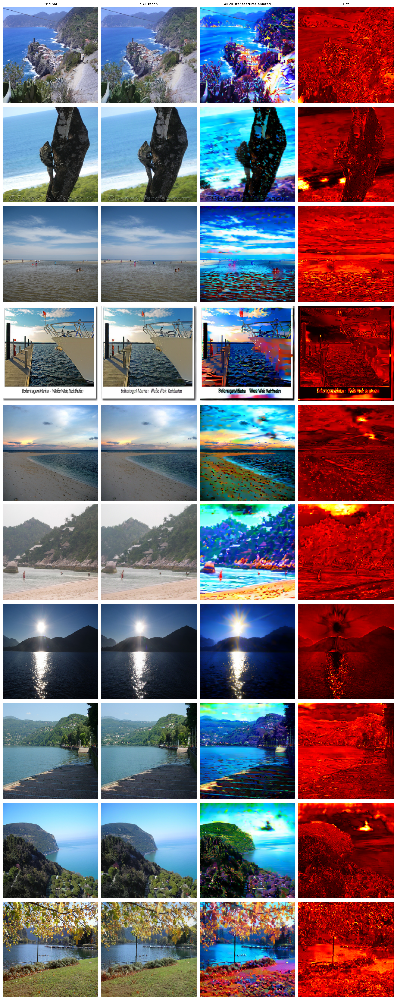

In [75]:
CLUSTER_ABLATE_N  = 10   
CLUSTER_STEER_X   = 3.0   

sample_imgs = cluster_indices[:CLUSTER_ABLATE_N]

fig, axes = plt.subplots(CLUSTER_ABLATE_N, 4, figsize=(16, 4 * CLUSTER_ABLATE_N))
if CLUSTER_ABLATE_N == 1:
    axes = axes[np.newaxis, :]
for col, title in enumerate(["Original", "SAE recon", "All cluster features ablated", "Diff"]):
    axes[0, col].set_title(title, fontsize=10)

ablate_scales = {fid: -1.0 for fid in CLUSTER_TOP_FEATURES}
steer_scales  = {fid: CLUSTER_STEER_X for fid in CLUSTER_TOP_FEATURES}

for row, img_idx in enumerate(sample_imgs):
    path, label_idx = dataset_plain.samples[img_idx]
    cls = dataset_plain.classes[label_idx]
    pil = Image.open(path).convert("RGB")
    tensor = transform(pil).unsqueeze(0).to(device)

    recon   = multi_feature_forward(tensor, {fid: 1.0 for fid in CLUSTER_TOP_FEATURES})
    ablated = multi_feature_forward(tensor, ablate_scales)

    diff = (recon - ablated).abs().mean(1, keepdim=True)
    diff_norm = (diff / diff.max().clamp_min(1e-8))[0, 0].cpu().numpy()

    axes[row, 0].imshow(pil.resize((256, 256)))
    axes[row, 1].imshow(to_np(recon[0]))
    axes[row, 2].imshow(to_np(ablated[0]))
    axes[row, 3].imshow(diff_norm, cmap="hot", vmin=0, vmax=1)
    axes[row, 0].set_ylabel(cls, fontsize=8)
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
out = os.path.join(OUTPUT_DIR, "cluster_ablation.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved → {out}")
plt.show()

Features fired in A only : 343
Features fired in B only : 403
Features fired in both   : 1488


/tmp/ipykernel_3160675/2479332766.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


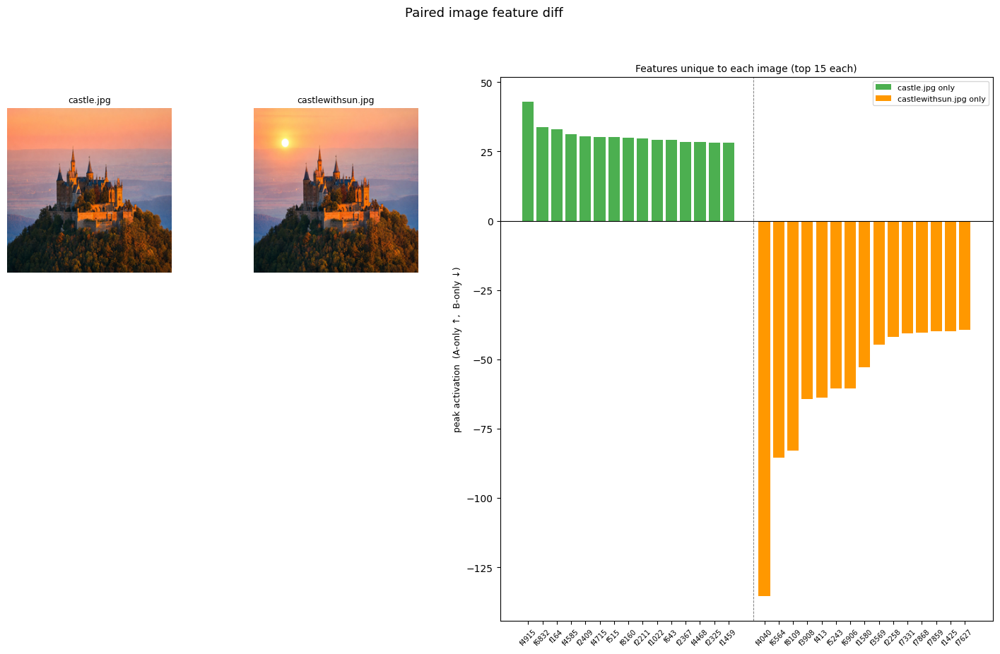


A-only feature IDs: [4915, 6832, 164, 4585, 2409, 4715, 515, 8160, 2211, 1022, 643, 2367, 4468, 2325, 1459]
B-only feature IDs: [4040, 6564, 8109, 3908, 413, 5243, 6906, 1580, 3569, 2258, 7331, 7868, 7859, 1425, 7627]


In [76]:
IMAGE_A_PATH = "/scratch/work/vuh12/UniTok/sae/castle.jpg"   
IMAGE_B_PATH = "/scratch/work/vuh12/UniTok/sae/castlewithsun.jpg"

TOP_K_PAIR   = 15    

transform = make_transform()

pil_a = Image.open(IMAGE_A_PATH).convert("RGB").resize((256, 256))
pil_b = Image.open(IMAGE_B_PATH).convert("RGB").resize((256, 256))
label_a = IMAGE_A_PATH.split("/")[-1]
label_b = IMAGE_B_PATH.split("/")[-1]

tensor_a = transform(pil_a).unsqueeze(0).to(device)
tensor_b = transform(pil_b).unsqueeze(0).to(device)

max_a, _ = get_sae_latent(tensor_a)
max_b, _ = get_sae_latent(tensor_b)
max_a, max_b = max_a.cpu(), max_b.cpu()

fired_a = max_a > 0
fired_b = max_b > 0

only_a = fired_a & ~fired_b
only_b = fired_b & ~fired_a

print(f"Features fired in A only : {only_a.sum().item()}")
print(f"Features fired in B only : {only_b.sum().item()}")
print(f"Features fired in both   : {(fired_a & fired_b).sum().item()}")

top_a_only = max_a[only_a].topk(min(TOP_K_PAIR, only_a.sum().item()))
ids_a_only = only_a.nonzero(as_tuple=True)[0][top_a_only.indices]

top_b_only = max_b[only_b].topk(min(TOP_K_PAIR, only_b.sum().item()))
ids_b_only = only_b.nonzero(as_tuple=True)[0][top_b_only.indices]

fig = plt.figure(figsize=(18, 10))
gs  = fig.add_gridspec(2, 3, width_ratios=[1, 1, 3], hspace=0.4, wspace=0.3)

ax_a   = fig.add_subplot(gs[0, 0])
ax_b   = fig.add_subplot(gs[0, 1])
ax_bar = fig.add_subplot(gs[:, 2])

ax_a.imshow(pil_a);  ax_a.set_title(label_a, fontsize=9);  ax_a.axis("off")
ax_b.imshow(pil_b);  ax_b.set_title(label_b, fontsize=9);  ax_b.axis("off")

n_a = len(ids_a_only)
n_b = len(ids_b_only)
x_a = np.arange(n_a)
x_b = np.arange(n_b) + n_a + 1.5

ax_bar.bar(x_a,  top_a_only.values.numpy(), color="#4caf50", label=f"{label_a} only")
ax_bar.bar(x_b, -top_b_only.values.numpy(), color="#ff9800", label=f"{label_b} only")
ax_bar.axhline(0, color="black", linewidth=0.8)
ax_bar.axvline(n_a + 0.75, color="gray", linewidth=0.7, linestyle="--")
ax_bar.set_xticks(np.concatenate([x_a, x_b]))
ax_bar.set_xticklabels([f"f{i}" for i in np.concatenate([ids_a_only.numpy(), ids_b_only.numpy()])],
                        rotation=45, fontsize=7)
ax_bar.set_ylabel("peak activation  (A-only ↑,  B-only ↓)", fontsize=9)
ax_bar.set_title(f"Features unique to each image (top {TOP_K_PAIR} each)", fontsize=10)
ax_bar.legend(fontsize=8)

plt.suptitle("Paired image feature diff", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "paired_diff.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"\nA-only feature IDs: {ids_a_only.tolist()}")
print(f"B-only feature IDs: {ids_b_only.tolist()}")

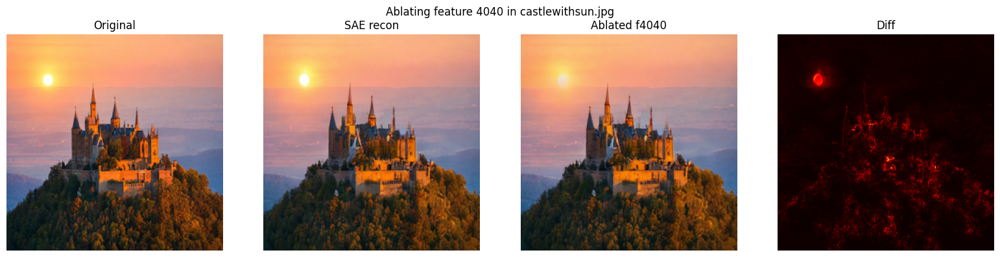

f4040 activation in castle.jpg:        0.00
f4040 activation in castlewithsun.jpg: 135.43


In [77]:
SUN_FEATURE = 4040

pil = Image.open(IMAGE_B_PATH).convert("RGB")
tensor = transform(pil).unsqueeze(0).to(device)

sae_recon = ablation_forward(tensor, SUN_FEATURE, scale=1.0)
ablated   = ablation_forward(tensor, SUN_FEATURE, scale=20.0)

diff = (sae_recon - ablated).abs().mean(dim=1)[0].cpu().numpy()
diff_norm = diff / max(diff.max(), 1e-8)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(pil.resize((256, 256)));        axes[0].set_title("Original")
axes[1].imshow(to_np(sae_recon[0]));           axes[1].set_title("SAE recon")
axes[2].imshow(to_np(ablated[0]));             axes[2].set_title(f"Ablated f{SUN_FEATURE}")
axes[3].imshow(diff_norm, cmap="hot");         axes[3].set_title("Diff")
for ax in axes: ax.axis("off")
plt.suptitle(f"Ablating feature {SUN_FEATURE} in castlewithsun.jpg", fontsize=12)
plt.tight_layout()
plt.show()

print(f"f{SUN_FEATURE} activation in castle.jpg:        {max_a[SUN_FEATURE].item():.2f}")
print(f"f{SUN_FEATURE} activation in castlewithsun.jpg: {max_b[SUN_FEATURE].item():.2f}")

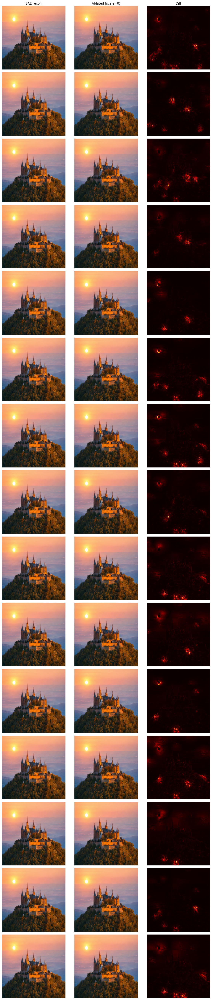

In [78]:
n = len(ids_b_only)
fig, axes = plt.subplots(n, 3, figsize=(12, 3.5 * n))

sae_recon = ablation_forward(tensor, ids_b_only[0].item(), scale=1.0)  # compute once

for row, fid in enumerate(ids_b_only.tolist()):
    ablated = ablation_forward(tensor, fid, scale=0.0)
    diff = (sae_recon - ablated).abs().mean(dim=1)[0].cpu().numpy()
    diff_norm = diff / max(diff.max(), 1e-8)

    axes[row, 0].imshow(to_np(sae_recon[0]))
    axes[row, 1].imshow(to_np(ablated[0]))
    axes[row, 2].imshow(diff_norm, cmap="hot")

    act = max_b[fid].item()
    axes[row, 0].set_ylabel(f"f{fid}\nact={act:.1f}", fontsize=8)
    if row == 0:
        axes[row, 0].set_title("SAE recon")
        axes[row, 1].set_title("Ablated (scale=0)")
        axes[row, 2].set_title("Diff")
    for ax in axes[row]: ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "b_only_ablations.png"), dpi=150, bbox_inches="tight")
plt.show()

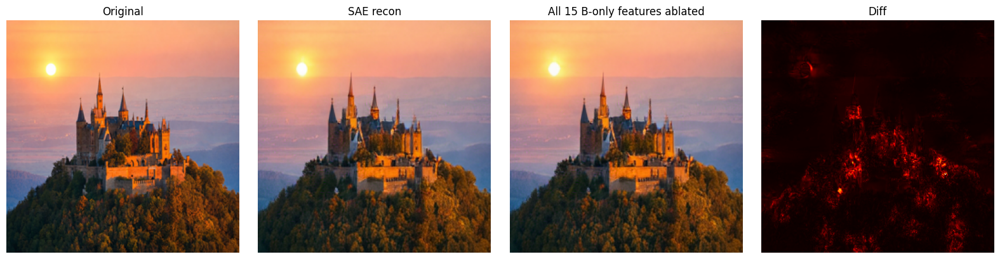

In [79]:
ablate_all_b = {fid: 0.0 for fid in ids_b_only.tolist()}

sae_recon = multi_feature_forward(tensor, {fid: 1.0 for fid in ids_b_only.tolist()})
ablated   = multi_feature_forward(tensor, ablate_all_b)

diff = (sae_recon - ablated).abs().mean(dim=1)[0].cpu().numpy()
diff_norm = diff / max(diff.max(), 1e-8)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(pil_b.resize((256, 256)));  axes[0].set_title("Original")
axes[1].imshow(to_np(sae_recon[0]));       axes[1].set_title("SAE recon")
axes[2].imshow(to_np(ablated[0]));         axes[2].set_title(f"All {len(ablate_all_b)} B-only features ablated")
axes[3].imshow(diff_norm, cmap="hot");     axes[3].set_title("Diff")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

# AutoPGD (L0)

In [80]:
import torch.nn.functional as F

def project_topk(delta, k):
    if (delta.abs() > 0).sum() <= k:
        return delta
    threshold = delta.abs().topk(k).values.min()
    return delta * (delta.abs() >= threshold).float()


def find_optimal_delta(
    tensor_a,
    tensor_b,
    k_sparse  = 10,
    n_steps   = 1000,
    step_size = 0.5,
    patience  = 50,
    min_delta = 1e-6,
    verbose   = True,
):
    with torch.no_grad():
        tgt_tokens = unitok.quant_proj(unitok.encoder(tensor_b).float()).detach() # (B, L, quant_dim)

    act_buffer = []
    def _collect(m, i, o): act_buffer.append(o.detach().float())
    handle = unitok.encoder.blocks[15].register_forward_hook(_collect)
    try:
        with torch.no_grad():
            unitok.encoder(tensor_a)
            src_acts = act_buffer[0]
    finally:
        handle.remove()

    B, L, D = src_acts.shape
    with torch.no_grad():
        src_latent, _, _, _ = sae.encode(src_acts.reshape(B * L, D))
        src_latent = src_latent.detach()

    k_check    = max(int(0.22 * n_steps), 1)
    size_decr  = max(int(0.03 * n_steps), 1)
    n_iter_min = max(int(0.06 * n_steps), 1)
    step_size_t    = torch.tensor(step_size, device=device)
    delta          = torch.zeros(sae.hidden_dim, device=device)
    delta_old      = delta.clone()
    delta_best     = delta.clone()
    loss_best      = torch.tensor(float('inf'), device=device)
    loss_steps     = []
    counter        = 0
    no_improve     = 0

    def _forward_with_delta(d):
        def _hook(module, inp, out):
            Bh, Lh, Dh = out.shape
            return sae.decode(src_latent + d.unsqueeze(0)).reshape(Bh, Lh, Dh).to(out.dtype)
        handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
        out = unitok.quant_proj(unitok.encoder(tensor_a).float())
        handle.remove()
        return out

    for step in range(n_steps):
        delta.requires_grad_(True)
        src_tokens = _forward_with_delta(delta)
        loss = F.mse_loss(src_tokens, tgt_tokens)
        grad = torch.autograd.grad(loss, delta)[0].detach()
        delta = delta.detach()

        threshold  = grad.abs().topk(k_sparse).values.min()
        sparsegrad = grad * (grad.abs() >= threshold).float()

        a         = 0.75 if step > 0 else 1.0
        grad2     = delta - delta_old
        delta_old = delta.clone()

        delta_1 = delta - step_size_t * sparsegrad.sign()
        delta   = project_topk(delta + (delta_1 - delta) * a + grad2 * (1 - a), k_sparse)

        with torch.no_grad():
            curr_loss = F.mse_loss(_forward_with_delta(delta), tgt_tokens)
        loss_steps.append(curr_loss.item())

        if curr_loss < loss_best - min_delta:
            delta_best = delta.clone()
            loss_best  = curr_loss.clone()
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= patience:
            if verbose:
                print(f"  early stop at step {step}  loss={loss_best.item():.6f}")
            break

        counter += 1
        if counter == k_check and step >= k_check:
            window = torch.tensor(loss_steps[step - k_check: step + 1])
            if (window[1:] > window[:-1]).float().mean() > 0.25:
                step_size_t = step_size_t / 2.0
                delta       = delta_best.clone()
                delta_old   = delta.clone()
            counter = 0
            k_check = max(k_check - size_decr, n_iter_min)

        if verbose and step % 50 == 0:
            print(f"  step {step:4d}  loss={curr_loss.item():.6f}  "
                  f"step_size={step_size_t.item():.4f}  "
                  f"nnz={(delta.abs() > 1e-6).sum().item()}")

    return delta_best.clone(), src_latent, loss_steps


@torch.no_grad()
def delta_forward(imgs, delta):
    def _hook(module, inp, out):
        B, L, D = out.shape
        latent, _, _, _ = sae.encode(out.float().reshape(B * L, D))
        latent = latent + delta.unsqueeze(0)
        return sae.decode(latent).reshape(B, L, D).to(out.dtype)
    handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
    try:
        img_tokens = unitok.encoder(imgs).float()
        img_tokens = unitok.quant_proj(img_tokens)
        img_tokens, _, _, _ = unitok.quantizer(img_tokens)
        img_tokens = unitok.post_quant_proj(img_tokens)
        img_rec    = unitok.decoder(img_tokens).clamp(-1, 1)
    finally:
        handle.remove()
    return denorm(img_rec)

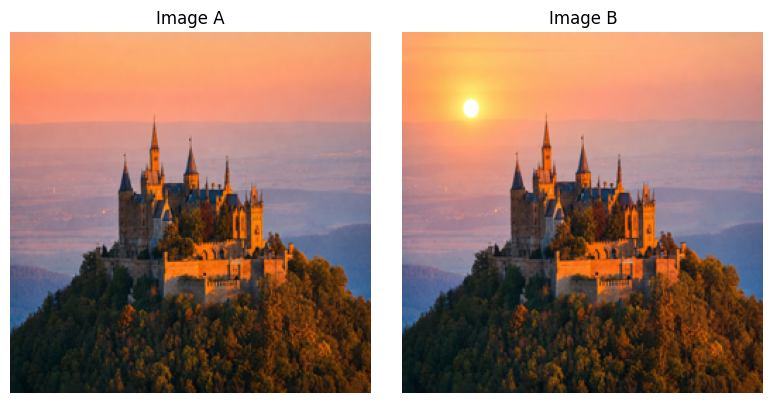

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(pil_a.resize((256, 256))); axes[0].set_title("Image A"); axes[0].axis("off")
axes[1].imshow(pil_b.resize((256, 256))); axes[1].set_title("Image B"); axes[1].axis("off")
plt.tight_layout(); plt.show()

In [82]:
K_SPARSE  = 50
N_STEPS   = 10000 # can change
STEP_SIZE = 0.5 # can change
PATIENCE  = 2000 # variable

print(f"Finding δ*  (k={K_SPARSE}, max_steps={N_STEPS}, patience={PATIENCE})")
delta, src_latent, loss_curve = find_optimal_delta(
    tensor_a, tensor_b,
    k_sparse  = K_SPARSE,
    n_steps   = N_STEPS,
    step_size = STEP_SIZE,
    patience  = PATIENCE,
)

Finding δ*  (k=50, max_steps=10000, patience=2000)
  step    0  loss=2.207399  step_size=0.5000  nnz=50
  step   50  loss=1.989132  step_size=0.5000  nnz=50
  step  100  loss=1.976874  step_size=0.5000  nnz=50
  step  150  loss=1.975158  step_size=0.5000  nnz=50
  step  200  loss=1.975158  step_size=0.5000  nnz=50
  step  250  loss=1.975158  step_size=0.5000  nnz=50
  step  300  loss=1.975158  step_size=0.5000  nnz=50
  step  350  loss=1.975158  step_size=0.5000  nnz=50
  step  400  loss=1.975158  step_size=0.5000  nnz=50
  step  450  loss=1.975158  step_size=0.5000  nnz=50
  step  500  loss=1.975158  step_size=0.5000  nnz=50
  step  550  loss=1.975158  step_size=0.5000  nnz=50
  step  600  loss=1.975158  step_size=0.5000  nnz=50
  step  650  loss=1.975158  step_size=0.5000  nnz=50
  step  700  loss=1.975158  step_size=0.5000  nnz=50
  step  750  loss=1.975158  step_size=0.5000  nnz=50
  step  800  loss=1.975158  step_size=0.5000  nnz=50
  step  850  loss=1.975158  step_size=0.5000  nn

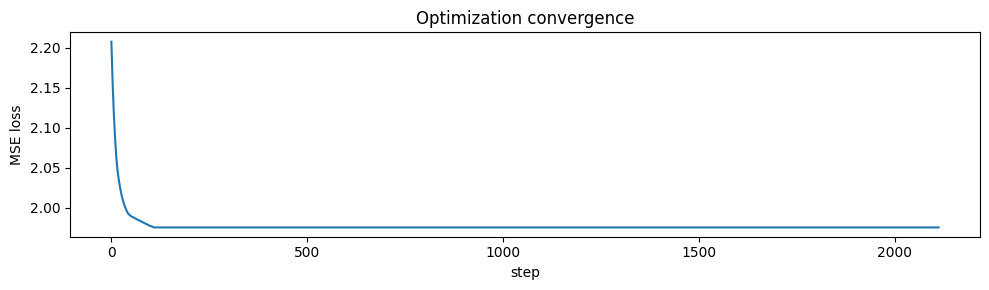

In [83]:
plt.figure(figsize=(10, 3))
plt.plot(loss_curve)
plt.xlabel("step"); plt.ylabel("MSE loss")
plt.title("Optimization convergence")
plt.tight_layout(); plt.show()

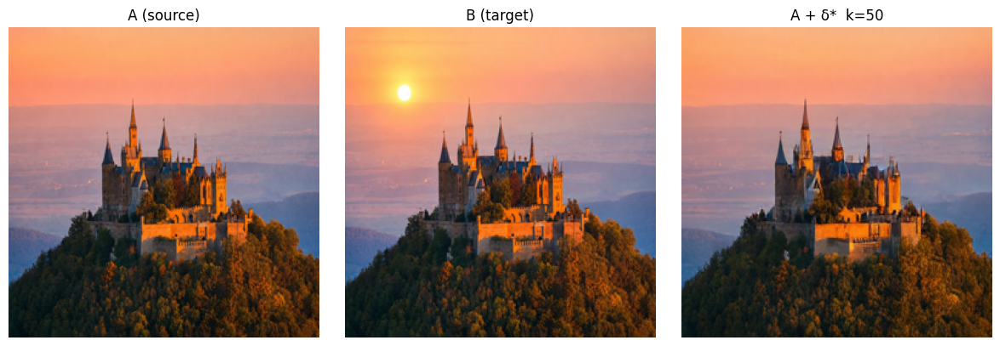

In [84]:
result = delta_forward(tensor_a, delta)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(pil_a.resize((256, 256))); axes[0].set_title("A (source)")
axes[1].imshow(pil_b.resize((256, 256))); axes[1].set_title("B (target)")
axes[2].imshow(to_np(result[0]));         axes[2].set_title(f"A + δ*  k={K_SPARSE}")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "optimized_delta.png"), dpi=150, bbox_inches="tight")
plt.show()

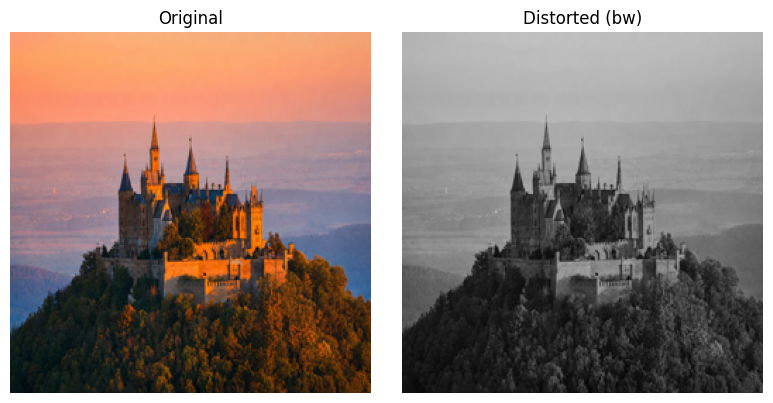

In [85]:
IMAGE_PATH   = "/scratch/work/vuh12/UniTok/sae/castle.jpg"
DISTORTION   = "bw"    
K_SPARSE     = 40
N_STEPS      = 5000
STEP_SIZE    = 0.5
PATIENCE     = 200

pil_orig = Image.open(IMAGE_PATH).convert("RGB").resize((256, 256))

if DISTORTION == "blur":
    from PIL import ImageFilter
    pil_dist = pil_orig.filter(ImageFilter.GaussianBlur(radius=5))

elif DISTORTION == "noise":
    import numpy as np
    arr  = np.array(pil_orig).astype(np.float32)
    arr += np.random.normal(0, 30, arr.shape)
    pil_dist = Image.fromarray(arr.clip(0, 255).astype(np.uint8))

elif DISTORTION == "bw":
    pil_dist = pil_orig.convert("L").convert("RGB")

elif DISTORTION == "jpeg":
    import io
    buf = io.BytesIO()
    pil_orig.save(buf, format="JPEG", quality=5)
    pil_dist = Image.open(buf).convert("RGB")

transform    = make_transform()
tensor_orig  = transform(pil_orig).unsqueeze(0).to(device)
tensor_dist  = transform(pil_dist).unsqueeze(0).to(device)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(pil_orig); axes[0].set_title("Original");              axes[0].axis("off")
axes[1].imshow(pil_dist); axes[1].set_title(f"Distorted ({DISTORTION})"); axes[1].axis("off")
plt.tight_layout(); plt.show()


In [86]:
print(f"Finding δ*: original → {DISTORTION}  (k={K_SPARSE})")
delta, src_latent, loss_curve = find_optimal_delta(
    tensor_orig, tensor_dist,
    k_sparse  = K_SPARSE,
    n_steps   = N_STEPS,
    step_size = STEP_SIZE,
    patience  = PATIENCE,
)

Finding δ*: original → bw  (k=40)
  step    0  loss=2.759962  step_size=0.5000  nnz=40
  step   50  loss=2.470495  step_size=0.5000  nnz=40
  step  100  loss=2.445085  step_size=0.5000  nnz=40
  step  150  loss=2.445085  step_size=0.5000  nnz=40
  step  200  loss=2.445085  step_size=0.5000  nnz=40
  step  250  loss=2.445085  step_size=0.5000  nnz=40
  step  300  loss=2.445085  step_size=0.5000  nnz=40
  early stop at step 301  loss=2.445084


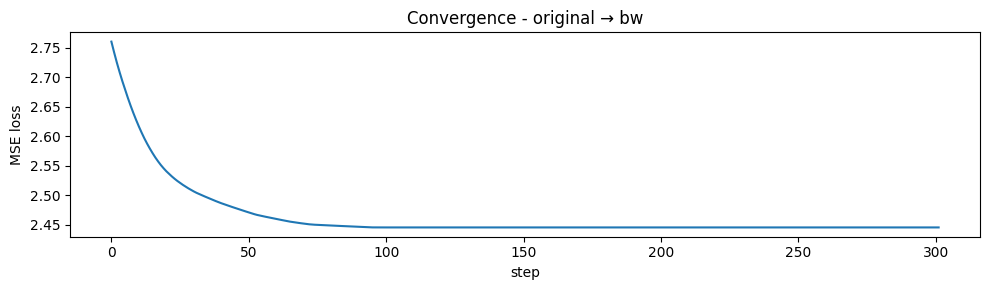

In [87]:
plt.figure(figsize=(10, 3))
plt.plot(loss_curve)
plt.xlabel("step"); plt.ylabel("MSE loss")
plt.title(f"Convergence - original → {DISTORTION}")
plt.tight_layout(); plt.show()

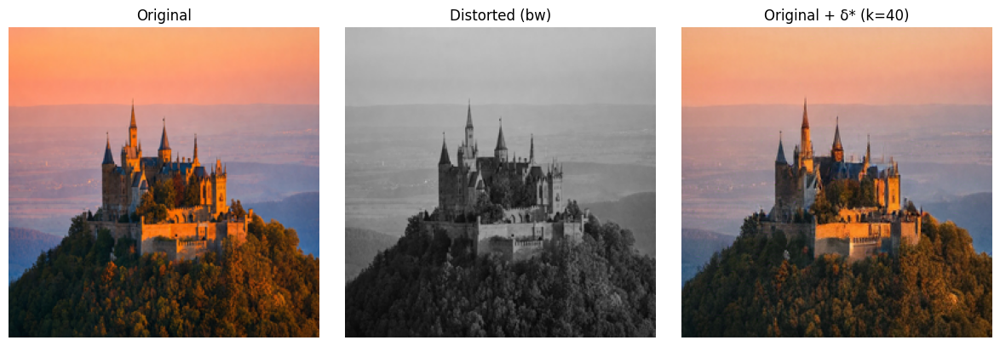

In [88]:
result = delta_forward(tensor_orig, delta)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(pil_orig);             axes[0].set_title("Original")
axes[1].imshow(pil_dist);             axes[1].set_title(f"Distorted ({DISTORTION})")
axes[2].imshow(to_np(result[0]));     axes[2].set_title(f"Original + δ* (k={K_SPARSE})")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"pgd_{DISTORTION}.png"), dpi=150, bbox_inches="tight")
plt.show()

## AutoPGD (L1)

In [37]:
def L1_projection(delta, eps):
    abs_d = delta.abs()
    if abs_d.sum() <= eps:
        return delta  \

    sorted_d, _ = abs_d.sort(descending=True)
    cumsum = sorted_d.cumsum(0)
    n      = torch.arange(1, len(sorted_d) + 1, device=delta.device, dtype=delta.dtype)

    rho   = ((sorted_d * n) > (cumsum - eps)).nonzero()[-1].item()
    theta = (cumsum[rho] - eps) / (rho + 1)

    return delta.sign() * (abs_d - theta).clamp(min=0)


def find_optimal_delta_l1(
    tensor_a,
    tensor_b,
    eps            = 500.0,  
    n_steps        = 1000,
    patience       = 50,
    min_delta      = 1e-6,
    verbose        = True,
):
    act_buffer = []
    def _collect(m, i, o): act_buffer.append(o.detach().float())
    handle = unitok.encoder.blocks[15].register_forward_hook(_collect)
    with torch.no_grad():
        act_buffer.clear(); unitok.encoder(tensor_a); src_acts = act_buffer[0]
        act_buffer.clear(); unitok.encoder(tensor_b); tgt_acts = act_buffer[0]
    handle.remove()

    B, L, D = src_acts.shape
    with torch.no_grad():
        src_latent, _, _, _ = sae.encode(src_acts.reshape(B * L, D))
        tgt_latent, _, _, _ = sae.encode(tgt_acts.reshape(B * L, D))
        tgt_recon  = sae.decode(tgt_latent).detach()
        src_latent = src_latent.detach()

    n_fts = sae.hidden_dim  

    alpha          = 1.0
    init_topk      = 0.05            
    adasp_redstep  = 1.5             
    adasp_minstep  = 10.0            
    k_check        = max(int(0.04 * n_steps), 1)

    step_size_t = torch.tensor(alpha * eps, device=device)   
    topk        = torch.tensor(init_topk, device=device)
    sp_old      = torch.tensor(float(n_fts), device=device)

    delta      = torch.zeros(n_fts, device=device)
    delta_old  = delta.clone()
    delta_best = delta.clone()
    grad_best  = torch.zeros_like(delta)
    loss_best  = torch.tensor(float('inf'), device=device)
    loss_steps = []
    counter    = 0
    no_improve = 0

    for step in range(n_steps):
        delta.requires_grad_(True)
        loss = F.mse_loss(sae.decode(src_latent + delta.unsqueeze(0)), tgt_recon)
        grad = torch.autograd.grad(loss, delta)[0].detach()
        delta = delta.detach()

        topk_curr      = int(torch.clamp((1.0 - topk) * n_fts,
                                          min=0, max=n_fts - 1).item())
        grad_sorted_asc = grad.abs().sort()[0]              # ascending
        grad_threshold  = grad_sorted_asc[topk_curr]
        sparsegrad      = grad * (grad.abs() >= grad_threshold).float()

        n_selected = sparsegrad.sign().abs().sum() + 1e-10
        delta_1    = delta - step_size_t * sparsegrad.sign() / n_selected

        delta_1 = L1_projection(delta_1, eps)

        a         = 0.75 if step > 0 else 1.0
        grad2     = delta - delta_old
        delta_old = delta.clone()

        delta_new = delta + (delta_1 - delta) * a + grad2 * (1 - a)
        delta     = L1_projection(delta_new, eps)   

        with torch.no_grad():
            curr_loss = F.mse_loss(sae.decode(src_latent + delta.unsqueeze(0)), tgt_recon)
        loss_steps.append(curr_loss.item())

        if curr_loss < loss_best - min_delta:
            delta_best = delta.clone()
            grad_best  = grad.clone()
            loss_best  = curr_loss.clone()
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= patience:
            if verbose:
                print(f"  early stop at step {step}  loss={loss_best.item():.6f}")
            break

        counter += 1
        if counter == k_check:
            sp_curr    = (delta_best.abs() > 1e-6).float().sum()  
            fl_redtopk = (sp_curr / sp_old) < 0.95          

            topk = (sp_curr / n_fts / 1.5).clamp(min=1e-6, max=init_topk)

            if fl_redtopk:
                step_size_t = torch.tensor(alpha * eps, device=device)
                delta       = delta_best.clone()
                delta_old   = delta.clone()
                grad        = grad_best.clone()
            else:
                step_size_t = step_size_t / adasp_redstep

            step_size_t = step_size_t.clamp(
                min = alpha * eps / adasp_minstep,
                max = alpha * eps,
            )
            sp_old  = sp_curr.clone()
            counter = 0

        if verbose and step % 50 == 0:
            nnz = (delta.abs() > 1e-6).sum().item()
            print(f"  step {step:4d}  loss={curr_loss.item():.6f}  "
                  f"step_size={step_size_t.item():.2f}  "
                  f"topk={topk.item():.4f}  nnz={nnz}")

    return delta_best.clone(), src_latent, tgt_latent, loss_steps

AutoPGD-L1  eps=40000.0  max_steps=2000  patience=1000
  step    0  loss=38928.585938  step_size=40000.00  topk=0.0500  nnz=410
  step   50  loss=11901.877930  step_size=40000.00  topk=0.0500  nnz=801
  step  100  loss=12602.241211  step_size=40000.00  topk=0.0500  nnz=1285
  step  150  loss=13316.552734  step_size=40000.00  topk=0.0500  nnz=724
  step  200  loss=2231.249512  step_size=26666.67  topk=0.0500  nnz=887
  step  250  loss=15175.505859  step_size=40000.00  topk=0.0500  nnz=921
  step  300  loss=17292.685547  step_size=40000.00  topk=0.0500  nnz=659
  step  350  loss=2764.684570  step_size=26666.67  topk=0.0500  nnz=674
  step  400  loss=315.038330  step_size=17777.78  topk=0.0500  nnz=678
  step  450  loss=2672.201172  step_size=17777.78  topk=0.0500  nnz=1202
  step  500  loss=10077.349609  step_size=40000.00  topk=0.0500  nnz=1024
  step  550  loss=10403.051758  step_size=40000.00  topk=0.0500  nnz=861
  step  600  loss=1180.367554  step_size=26666.67  topk=0.0500  nnz=105

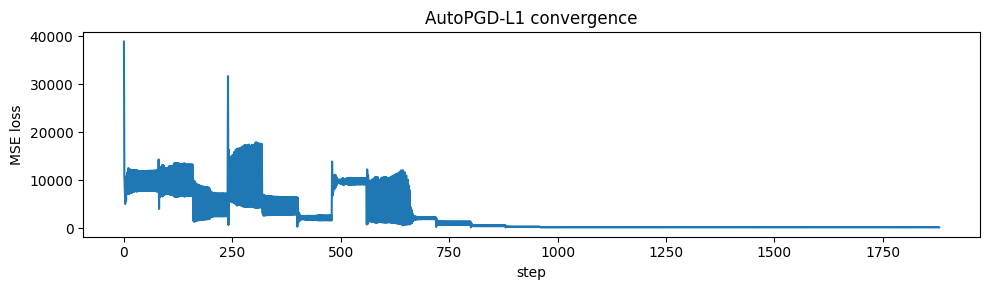

In [38]:
EPS       = 40000.0  
N_STEPS   = 2000
PATIENCE  = 1000

print(f"AutoPGD-L1  eps={EPS}  max_steps={N_STEPS}  patience={PATIENCE}")
delta_l1, src_latent, tgt_latent, loss_curve = find_optimal_delta_l1(
    tensor_a, tensor_b,
    eps      = EPS,
    n_steps  = N_STEPS,
    patience = PATIENCE,
)

plt.figure(figsize=(10, 3))
plt.plot(loss_curve)
plt.xlabel("step"); plt.ylabel("MSE loss")
plt.title("AutoPGD-L1 convergence")
plt.tight_layout(); plt.show()

In [39]:
with torch.no_grad():
    tgt_recon = sae.decode(tgt_latent)
    baseline  = F.mse_loss(sae.decode(src_latent), tgt_recon)
    optimized = F.mse_loss(sae.decode(src_latent + delta_l1.unsqueeze(0)), tgt_recon)
print(f"Baseline loss: {baseline.item():.3f}")
print(f"Optimized:     {optimized.item():.3f}")
print(f"Reduction:     {(1 - optimized/baseline)*100:.1f}%")

Baseline loss: 77.271
Optimized:     146.337
Reduction:     -89.4%


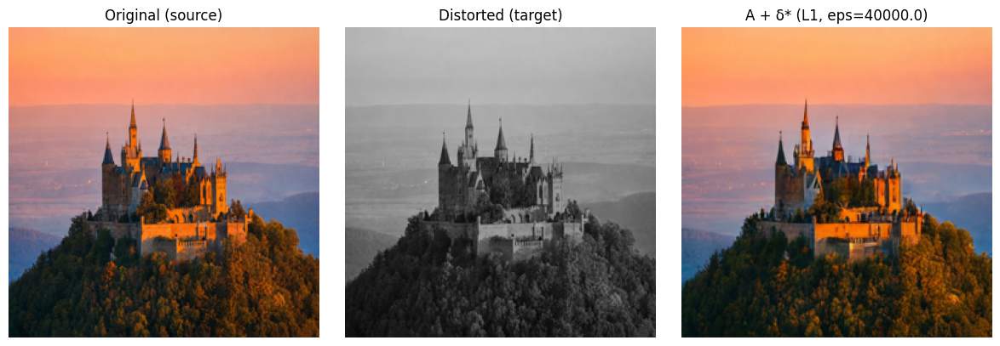

In [40]:
result = delta_forward(tensor_orig, delta_l1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(pil_orig.resize((256, 256))); axes[0].set_title("Original (source)")
axes[1].imshow(pil_dist.resize((256, 256))); axes[1].set_title("Distorted (target)")
axes[2].imshow(to_np(result[0]));         axes[2].set_title(f"A + δ* (L1, eps={EPS})")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "pgd_l1.png"), dpi=150, bbox_inches="tight")
plt.show()

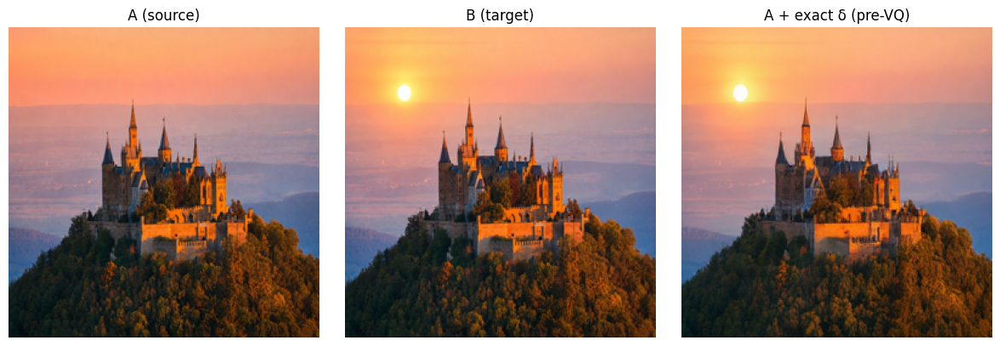

In [41]:
@torch.no_grad()
def diagnose_prevq(tensor_a, tensor_b):
    src_prevq = unitok.quant_proj(unitok.encoder(tensor_a).float())  # (1, 64, d)
    tgt_prevq = unitok.quant_proj(unitok.encoder(tensor_b).float())  # (1, 64, d)
    delta_prevq = tgt_prevq - src_prevq  

    shifted = src_prevq + delta_prevq 
    img_tokens, _, _, _ = unitok.quantizer(shifted)
    img_tokens = unitok.post_quant_proj(img_tokens)
    img_rec = denorm(unitok.decoder(img_tokens).clamp(-1, 1))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(pil_a.resize((256, 256))); axes[0].set_title("A (source)")
    axes[1].imshow(pil_b.resize((256, 256))); axes[1].set_title("B (target)")
    axes[2].imshow(to_np(img_rec[0]));        axes[2].set_title("A + exact δ (pre-VQ)")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

diagnose_prevq(tensor_a, tensor_b)

  step    0  loss=2.226453  |δ|_max=0.0008
  step   50  loss=2.206873  |δ|_max=0.0392
  step  100  loss=2.189066  |δ|_max=0.0756
  step  150  loss=2.172812  |δ|_max=0.1102
  step  200  loss=2.157923  |δ|_max=0.1433
  step  250  loss=2.144241  |δ|_max=0.1749
  step  300  loss=2.131633  |δ|_max=0.2051
  step  350  loss=2.119980  |δ|_max=0.2342
  step  400  loss=2.109183  |δ|_max=0.2620
  step  450  loss=2.099155  |δ|_max=0.2889
  step  500  loss=2.089819  |δ|_max=0.3147
  step  550  loss=2.081109  |δ|_max=0.3397
  step  600  loss=2.072964  |δ|_max=0.3637
  step  650  loss=2.065335  |δ|_max=0.3870
  step  700  loss=2.058174  |δ|_max=0.4095
  step  750  loss=2.051440  |δ|_max=0.4314
  step  800  loss=2.045098  |δ|_max=0.4525
  step  850  loss=2.039113  |δ|_max=0.4730
  step  900  loss=2.033458  |δ|_max=0.4929
  step  950  loss=2.028105  |δ|_max=0.5122
  step 1000  loss=2.023031  |δ|_max=0.5309
  step 1050  loss=2.018214  |δ|_max=0.5492
  step 1100  loss=2.013635  |δ|_max=0.5669
  step 1150

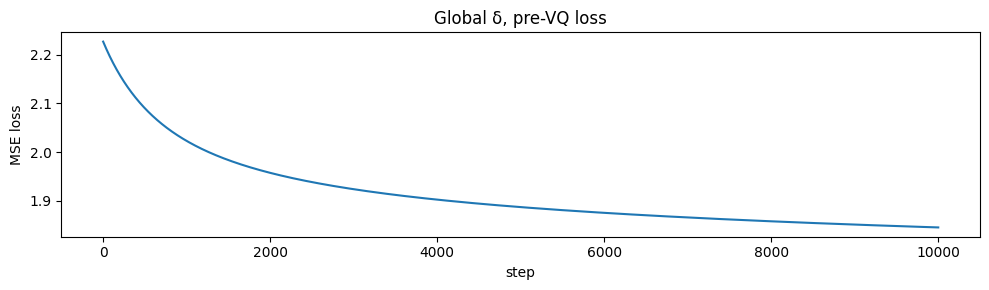

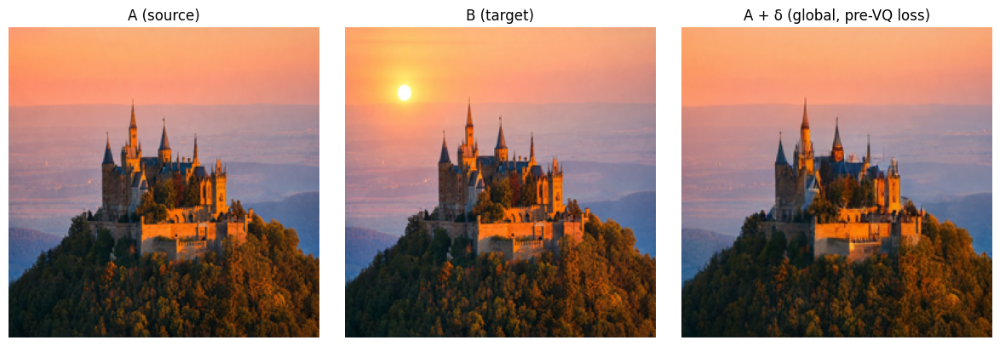


rank   feature           δ
   1      1232     +1.7574
   2      5092     -1.6716
   3      7747     +1.6329
   4      4962     +1.6095
   5      1769     -1.5653
   6      7454     -1.5632
   7       566     -1.5420
   8      7933     -1.5331
   9      7720     -1.4952
  10      7271     -1.4844
  11      2023     +1.4499
  12      1961     +1.4490
  13      8010     -1.4467
  14      3187     -1.4290
  15      7661     +1.4182
  16      4037     -1.4178
  17      7552     -1.4119
  18      1333     -1.4072
  19      5286     +1.3926
  20       273     -1.3924


In [45]:
# Delta (1, 8292) and MSE loss between pre-VQ tokens
def find_delta_prevq(tensor_a, tensor_b, lr=1.0, n_steps=500, verbose=True):
    with torch.no_grad():
        tgt_tokens = unitok.quant_proj(unitok.encoder(tensor_b).float()).detach()

    # Pre-compute block-15 SAE latent for A    
    act_buffer = []
    def _collect(m, i, o): act_buffer.append(o.detach().float())
    handle = unitok.encoder.blocks[15].register_forward_hook(_collect)
    with torch.no_grad():
        unitok.encoder(tensor_a)
        src_acts = act_buffer[0]
    handle.remove()

    B, L, D = src_acts.shape
    with torch.no_grad():
        src_latent, _, _, _ = sae.encode(src_acts.reshape(B * L, D))
        src_latent = src_latent.detach()

    delta = torch.zeros(sae.hidden_dim, device=device)
    loss_steps = []

    for step in range(n_steps):
        delta.requires_grad_(True)

        def _hook(module, inp, out):
            Bh, Lh, Dh = out.shape
            return sae.decode(src_latent + delta.unsqueeze(0)).reshape(Bh, Lh, Dh).to(out.dtype)

        handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
        src_tokens = unitok.quant_proj(unitok.encoder(tensor_a).float())
        handle.remove()

        loss = F.mse_loss(src_tokens, tgt_tokens)
        grad = torch.autograd.grad(loss, delta)[0].detach()
        delta = delta.detach()

        delta = delta - lr * grad

        loss_steps.append(loss.item())
        if verbose and step % 50 == 0:
            print(f"  step {step:4d}  loss={loss.item():.6f}  "
                  f"|δ|_max={delta.abs().max().item():.4f}")

    return delta, src_latent, loss_steps


delta, src_latent, loss_curve = find_delta_prevq(
    tensor_a, tensor_b, lr=0.75, n_steps=10000
)

plt.figure(figsize=(10, 3))
plt.plot(loss_curve)
plt.xlabel("step"); plt.ylabel("MSE loss")
plt.title("Global δ, pre-VQ loss")
plt.tight_layout(); plt.show()

result = delta_forward(tensor_a, delta)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(pil_a.resize((256, 256))); axes[0].set_title("A (source)")
axes[1].imshow(pil_b.resize((256, 256))); axes[1].set_title("B (target)")
axes[2].imshow(to_np(result[0]));         axes[2].set_title("A + δ (global, pre-VQ loss)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# ── Top features by |δ| ───────────────────────────────────────────────────────
top20 = delta.abs().topk(20)
print(f"\n{'rank':>4}  {'feature':>8}  {'δ':>10}")
for i, (val, idx) in enumerate(zip(top20.values, top20.indices)):
    print(f"{i+1:>4}  {idx.item():>8}  {delta[idx].item():>+10.4f}")

  step    0  loss=2.226453  |δ|_max=0.0021
  step   50  loss=2.168196  |δ|_max=0.1054
  step  100  loss=2.113822  |δ|_max=0.2098
  step  150  loss=2.062952  |δ|_max=0.3152
  step  200  loss=2.015251  |δ|_max=0.4216
  step  250  loss=1.970401  |δ|_max=0.5288
  step  300  loss=1.928099  |δ|_max=0.6368
  step  350  loss=1.888060  |δ|_max=0.7463
  step  400  loss=1.850035  |δ|_max=0.8567
  step  450  loss=1.813808  |δ|_max=0.9679
  step  500  loss=1.779199  |δ|_max=1.0797
  step  550  loss=1.746053  |δ|_max=1.1922
  step  600  loss=1.714238  |δ|_max=1.3052
  step  650  loss=1.683642  |δ|_max=1.4187
  step  700  loss=1.654165  |δ|_max=1.5326
  step  750  loss=1.625721  |δ|_max=1.6468
  step  800  loss=1.598235  |δ|_max=1.7613
  step  850  loss=1.571639  |δ|_max=1.8760
  step  900  loss=1.545873  |δ|_max=1.9908
  step  950  loss=1.520886  |δ|_max=2.1057
  step 1000  loss=1.496629  |δ|_max=2.2207
  step 1050  loss=1.473060  |δ|_max=2.3356
  step 1100  loss=1.450143  |δ|_max=2.4505
  step 1150

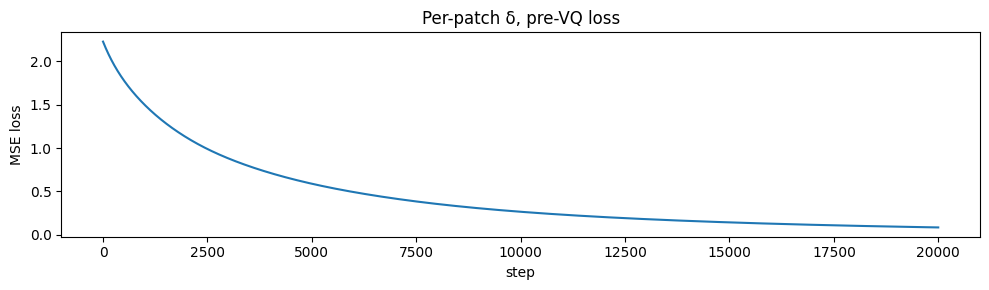

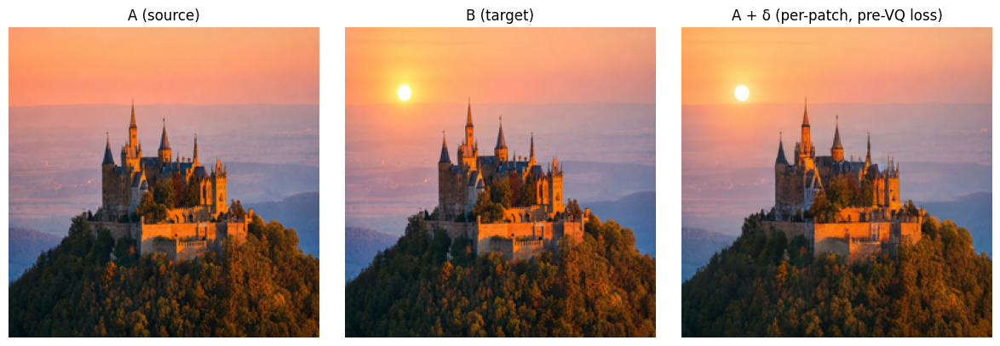

In [89]:
def find_delta_patchwise_prevq(tensor_a, tensor_b, lr=1.0, n_steps=500, verbose=True):
    with torch.no_grad():
        tgt_tokens = unitok.quant_proj(unitok.encoder(tensor_b).float()).detach()

    act_buffer = []
    def _collect(m, i, o): act_buffer.append(o.detach().float())
    handle = unitok.encoder.blocks[15].register_forward_hook(_collect)
    try:
        with torch.no_grad():
            unitok.encoder(tensor_a)
            src_acts = act_buffer[0]
    finally:
        handle.remove()

    B, L, D = src_acts.shape
    with torch.no_grad():
        src_latent, _, _, _ = sae.encode(src_acts.reshape(B * L, D))
        src_latent = src_latent.detach()

    delta = torch.zeros(L, sae.hidden_dim, device=device)  # (64, 8192)
    loss_steps = []

    for step in range(n_steps):
        delta.requires_grad_(True)

        def _hook(module, inp, out):
            Bh, Lh, Dh = out.shape
            return sae.decode(src_latent + delta).reshape(Bh, Lh, Dh).to(out.dtype)

        handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
        try:
            src_tokens = unitok.quant_proj(unitok.encoder(tensor_a).float())
        finally:
            handle.remove()

        loss = F.mse_loss(src_tokens, tgt_tokens)
        grad = torch.autograd.grad(loss, delta)[0].detach()
        delta = delta.detach()

        delta = delta - lr * grad

        loss_steps.append(loss.item())
        if verbose and step % 50 == 0:
            print(f"  step {step:4d}  loss={loss.item():.6f}  "
                  f"|δ|_max={delta.abs().max().item():.4f}")

    return delta, src_latent, loss_steps


delta_pw, src_latent, loss_curve = find_delta_patchwise_prevq(
    tensor_a, tensor_b, lr=15.0, n_steps=20000
)

plt.figure(figsize=(10, 3))
plt.plot(loss_curve)
plt.xlabel("step"); plt.ylabel("MSE loss")
plt.title("Per-patch δ, pre-VQ loss")
plt.tight_layout(); plt.show()


@torch.no_grad()
def delta_patchwise_forward(imgs, delta):
    def _hook(module, inp, out):
        B, L, D = out.shape
        latent, _, _, _ = sae.encode(out.float().reshape(B * L, D))
        latent = latent + delta
        return sae.decode(latent).reshape(B, L, D).to(out.dtype)
    handle = unitok.encoder.blocks[15].register_forward_hook(_hook)
    try:
        img_tokens = unitok.encoder(imgs).float()
        img_tokens = unitok.quant_proj(img_tokens)
        img_tokens, _, _, _ = unitok.quantizer(img_tokens)
        img_tokens = unitok.post_quant_proj(img_tokens)
        img_rec = unitok.decoder(img_tokens).clamp(-1, 1)
    finally:
        handle.remove()
    return denorm(img_rec)

result = delta_patchwise_forward(tensor_a, delta_pw)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(pil_a.resize((256, 256))); axes[0].set_title("A (source)")
axes[1].imshow(pil_b.resize((256, 256))); axes[1].set_title("B (target)")
axes[2].imshow(to_np(result[0]));         axes[2].set_title("A + δ (per-patch, pre-VQ loss)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()